# Introduction to Machine Learning -- MC886
# Assignment 1 - Linear Models

**Professor:** Marcelo da Silva Reis\
**PED:** Heigon Alafaire Soldera Pires


In [1]:
# Please, enter your name and RA number in the lines below:
print(f"{"Matheus Hencklein Ponte":32}", "|", "247277")
print(f"{"Álvaro Brandão de Carvalho":32}", "|", "195033")
print(f"{"Henrique Cazarim Meirelles Alves":32}", "|", "24763") # You may remove this line if you are only 2 students in the group

Matheus Hencklein Ponte          | 247277
Álvaro Brandão de Carvalho       | 195033
Henrique Cazarim Meirelles Alves | 24763



## Objective

The objective with this assignment is to explore **Linear Regression** and other
**Generalized Linear Models** to come up with the best model for the problem.
Remember, the goal is not just getting the code running, but gathering a deeper
understanding on **how** these algorithms work and **why** choosing them in the
first place.

Every model choice has implicit assumptions about the data, the goal here is to
understand the underlying assumptions and critically address the limitations
introduced by them.

### **Guidelines**
> Please, read these guidelines carefully

1. The questions can be answered in English or in Portuguese.

2. We incentivize visualizing the (training) data to gather insight about the
problem and the solutions. If you are not sure about an assumption, plot it!

3. The existing code in this notebook is just a mere reference. You are free to
change the code as much as you need. You will not be penalized for changing a 
function signature or implementing more functions/classes.
**Just make the code readable!**

4. The use of generative AI (ChatGPT, DeepSeek, Llama, GitHub Copilot, etc.) is
permitted to assist in completing assignments. In such cases the submitted work
**must** include a statement specifying the models used and, if
applicable, a transcription of the prompts employed to generate the code
incorporated into the solution.
However, using AI to analyse and discuss the results is discouraged.

5. The final performance of your model is not the main goal, explaining why the
model has such a performance (it being good or bad) is more important than the
metric value per se.

6. Metrics are not detached values, revisit the math behind them to understand
what they are trying to say about your model.

7. Do not hesitate in reaching the PED via Discord.

---
### **Dataset**
The dataset we will be using is the [Metro Interstate Traffic Volume](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume)
dataset, an hourly count of vehicles on the westbound Interstate 94, measured by
the MnDOT sensor ATR 301, roughly midway between Minneapolis and St. Paul (MN),
between 2015 and 2018.
Each observation joins the traffic counter with the weather reported for that
same hour and with the holiday calendar.

The data has 26677 samples with the following columns

feature | description | data type
--- | --- | ---
**instant** | Integer identifier | Integer
**date** | Date of the observation | Date
**season** | The season (1 Winter, 2 Spring, 3 Summer, 4 Fall) | Categorical
**yr** | Year (0 for 2015, 1 for 2016, 2 for 2017 and 3 for 2018) | Categorical
**mnth** | The month number | Categorical
**hr** | The hour number | Categorical
**holiday** | Whether the day is a national holiday (or the Minnesota State Fair) | Boolean
**weekday** | The day of the week (0 is Sunday) | Categorical
**workingday** | If the day is neither a holiday nor a weekend | Boolean
**weather** | Current weather (Clear, Clouds, Rain, Snow, Mist, ...) | Categorical
**weather_desc** | A longer description of the current weather | Categorical
**temp** | Temperature in °C | Continuous
**rain_1h** | Rain that fell during the hour, in mm | Continuous
**snow_1h** | Snow that fell during the hour, in mm | Continuous
**clouds_all** | Cloud cover in % | Continuous
**traffic_volume** | Count of vehicles reported in the hour | Integer

The goal will be inferring the traffic volume of an hour only using datetime and
weather information provided in the dataset.

> **Note:** this data comes from real sensors and was only lightly cleaned for
> you. Some hours are absent from the record and a few readings are physically
> implausible. Deciding what (if anything) to do about them is part of the
> assignment.

*Source: Hogue, J. (2019). Metro Interstate Traffic Volume. UCI Machine Learning
Repository (CC BY 4.0).*


In [2]:
# Importing the necessary libraries
# Remember to re-visit the Hands-on 1 notebooks to setup your environment
from numpy.typing import NDArray
import numpy as np

import pandas as pd
import random

# This notebook already has some plot examples in matplotlib, but feel free to
# use other libraries (e.g., seaborn, plotly) if you prefer
import matplotlib.pyplot as plt

# To ensure reproducibility, set the random seed to your
# favorite number (e.g., your RA number)
np.random.seed(42)
random.seed(42)

# Do not tune this number to get better results, it is just to ensure that
# we all have the same random numbers and, therefore, the same results
# Re-run the notebook from the beginning (Run All) before submitting to classroom

In [3]:
# The dataset is available in the classroom assignment, ensure you have downloaded
# it and placed it in the same folder as this notebook

# Load the dataset
df = pd.read_csv("traffic_volume.csv")

df["date"] = pd.to_datetime(df["date"])
df.head()


,instant,date,season,yr,mnth,hr,holiday,weekday,workingday,weather,weather_desc,temp,rain_1h,snow_1h,clouds_all,traffic_volume
0,1,2015-06-11,3,0,6,20,0,4,1,Rain,light rain,14.44,0.0,0.0,92,2886
1,2,2015-06-12,3,0,6,18,0,5,1,Clear,Sky is Clear,24.39,0.0,0.0,0,4380
2,3,2015-06-12,3,0,6,20,0,5,1,Clear,sky is clear,18.91,0.0,0.0,8,3095
3,4,2015-06-12,3,0,6,21,0,5,1,Clear,sky is clear,18.91,0.0,0.0,8,3299
4,5,2015-06-13,3,0,6,21,0,6,0,Clouds,broken clouds,21.69,0.0,0.0,76,3040


Note that the data is time-ordered, and consecutive samples are (usually) 1 hour
apart from each other. Beware that the record is not perfectly regular: some
hours were never reported by the sensor.
The idea is to predict future traffic volume from past data, thus our evaluation
protocol must respect the temporal order.
Therefore, we select the first 80% samples to compose the training data, and the
remaining 20% will be used for testing purposes.

**Important:** Never take decisions over the test dataset, it must be only used after
all models are trained (in the Test Evaluation section).
Any decision made using test information is called [data leakage](https://en.wikipedia.org/wiki/Leakage_(machine_learning)) and will be penalized.


In [4]:
train_size = int(0.8 * len(df))

train_df = df[:train_size]
test_df = df[train_size:]

# Securing that df will not be used anymore, to avoid mistakes
del df

print("Train set size:", len(train_df))
print("Test set size:", len(test_df))

Train set size: 21341
Test set size: 5336


---

## **Data Analysis and Preprocessing**

This part of the assignment aims to analyze the dataset and preprocess
the data for the models.


(0.5 points) 
First, consider possible problems in your dataset:
- Should you use all the features in the dataset?
- What features are important, are there missing values in them?
- Are there outliers in continous features?
- How should you handle the categorical features?
- How does the traffic volume change when features change?
- Are these feature correlated?

Do not plot any graph for now, just see some statistics (mean, count, data types).
You can manually explore the dataframe if you want.

In [5]:
train_df.describe()

,instant,date,season,yr,mnth,hr,holiday,weekday,workingday,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,21341.000000,21341,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000
mean,10671.000000,2016-11-16 00:53:50.738953,2.574809,1.352092,6.813177,11.471346,0.032707,3.000984,0.680943,9.058459,0.520919,0.000223,41.742749,3277.748981
min,1.000000,2015-06-11 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,-29.760000,0.000000,0.000000,0.000000,0.000000
25%,5336.000000,2016-04-16 00:00:00,1.000000,1.000000,4.000000,5.000000,0.000000,1.000000,0.000000,0.020000,0.000000,0.000000,1.000000,1250.000000
50%,10671.000000,2016-11-29 00:00:00,3.000000,1.000000,7.000000,11.000000,0.000000,3.000000,1.000000,11.080000,0.000000,0.000000,40.000000,3446.000000
75%,16006.000000,2017-07-12 00:00:00,4.000000,2.000000,10.000000,18.000000,0.000000,5.000000,1.000000,19.170000,0.000000,0.000000,90.000000,4915.000000
max,21341.000000,2018-02-19 00:00:00,4.000000,3.000000,12.000000,23.000000,1.000000,6.000000,1.000000,34.180000,9831.300000,0.510000,100.000000,7280.000000
std,6160.760383,NaN,1.143291,0.822834,3.447233,6.953911,0.177873,2.002400,0.466122,12.523845,67.301383,0.007825,39.245090,1964.269523


> **Question:**
>
> Which of the previous questions can you properly answer without visualizing the data?
> What decisions can be made right now?

**Answers:**
1. Can be answered. No. Since we are trying to predict the traffic volume (our label, or Y) based on the "date" (X1), "hr" (X2) and "weather" features (X3) only, we don't need to look at any of the other ones.
2. Can be answered. The important features are "traffic volume", "date", "hr" and "weather". By visualizing the `count` row on the previous table (output of `train_df.describe()`), the value of the first two features are equal to `train_size`, meaning the data of there features are complete for every data point. Although "weather" is not present on the table, it's possible to see the count of elements on its row:

In [6]:
train_df["weather"].count()

np.int64(21341)

2. (cont) which means there's weather data for each point.

3. Can be answered. For traffic volume, hr and date, based on the description table, it doesn't seem there are outliers because all of the variables are on the expected range, such as "date" ranging from 2015 to 2018 and "hr" ranging from 0 to 23. Also, there are no negative or obviously overestimated values for "traffic". To see any unusual behavior on "weather", let's look at the unique values the column has:

In [7]:
train_df["weather"].unique()

<StringArray>
[        'Rain',        'Clear',       'Clouds',         'Haze',
 'Thunderstorm',         'Mist',      'Drizzle',          'Fog',
        'Smoke',         'Snow']
Length: 10, dtype: str

3. (cont) No unexpected values here, so no outliers. 

4. Can be answered. A way to handle categorical features is by using 'dummy' variables. Each class must constitute its own feature, in order to avoid order relations between them, using a technique called "one-hot encoding". 

5. Can't be answered without looking at the data. The expected behavior is that the traffic volume must be higher at daytime and mild weather, such as "Clear", "Clouds" and "Rain", and lower at nighttime and severe weather (Thunderstorm, Snow), but there's no way to be sure without looking at plots or the data itself.

6. Probably, but again there's no way to be sure without looking at the data or plotting. 

---
(1.0 points) Now, explore the raw data, visualize their relationship with the target `traffic_volume`.
You can use boxplots to understand feature distributions, histograms to observe
the count frequency, explore the temporal correlation.

There is no minimum/maximum requirements for the exploratory data analysis, plot
as many graphs as you need to gather information from your problem.
After plotting, write about your findings, formulate hypothesis about unseen
patterns and ponder about the data preprocessing step.

Firstly, an Average Traffic Volume plot in function of the Hour of the Day, from 0 to 23.

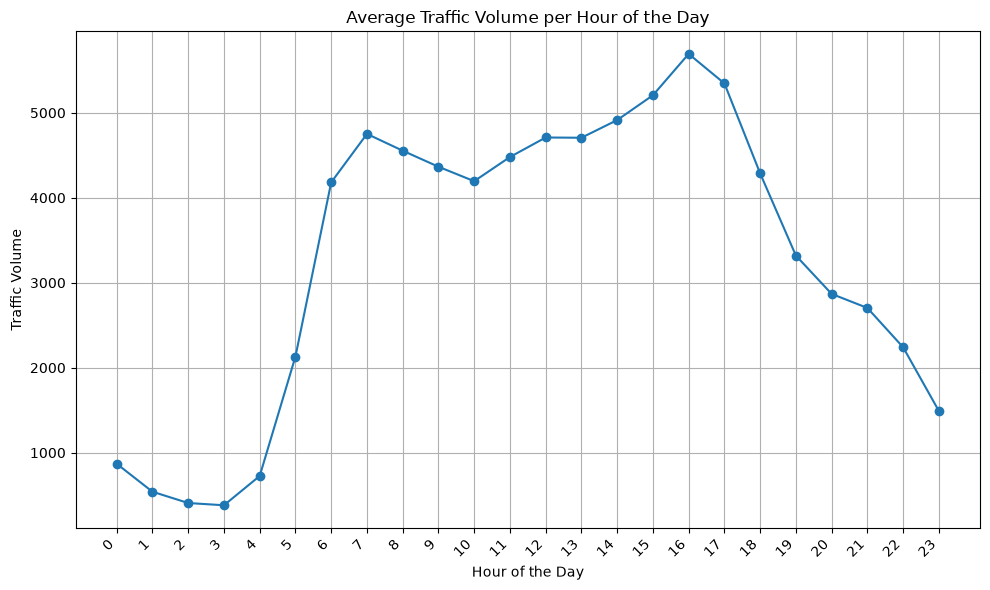

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.grid()

timestamp = train_df["date"] + pd.to_timedelta(train_df['hr'], unit='h')

# Mean traffic volume per hour of the day
hourly_counts = train_df.groupby("hr")["traffic_volume"].mean()
ax.plot(hourly_counts.index, hourly_counts.values, marker="o")

ax.set_xlabel("Hour of the Day")
ax.set_ylabel("Traffic Volume")
ax.set_title("Average Traffic Volume per Hour of the Day")

plt.xticks(hourly_counts.index)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Finding the range and percentage of decay on values:

In [9]:
max_hour_avg = hourly_counts.max()
min_hour_avg = hourly_counts.min()
difference_on_avg = max_hour_avg - min_hour_avg
perc_decay_avg = (difference_on_avg/max_hour_avg) * 100
print(f"Difference between max and min average = {difference_on_avg:.2f}")
print(f"Percentage of decay = {perc_decay_avg:.2f}")

Difference between max and min average = 5312.17
Percentage of decay = 93.30


Second, Average Traffic Volume plot in function of date:

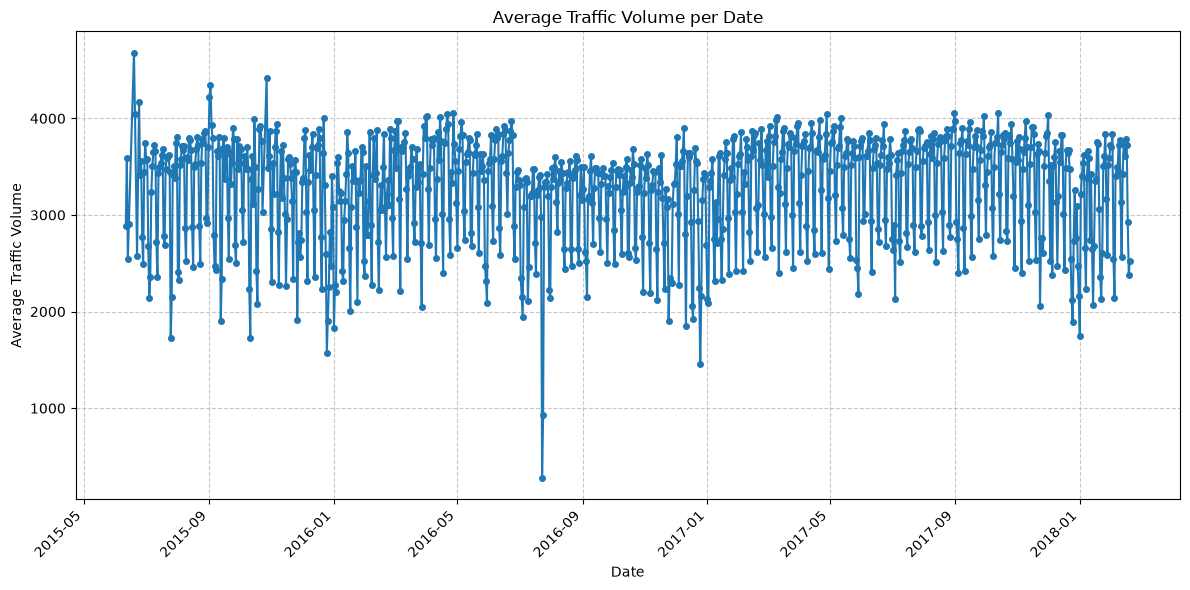

In [10]:
train_df["date"] = pd.to_datetime(train_df["date"])

daily_counts = train_df.groupby("date")["traffic_volume"].mean()

fig, ax = plt.subplots(figsize=(12, 6))
ax.grid(True, linestyle="--", alpha=0.7)

ax.plot(daily_counts.index, daily_counts.values, marker="o", linestyle="-", markersize=4)

ax.set_xlabel("Date")
ax.set_ylabel("Average Traffic Volume")
ax.set_title("Average Traffic Volume per Date")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

Finally, a plot of the Average Traffic Volume in terms of Weather Condition. Since the weather is a categorical and not a time-related class, a barplot is the most adequate graph.

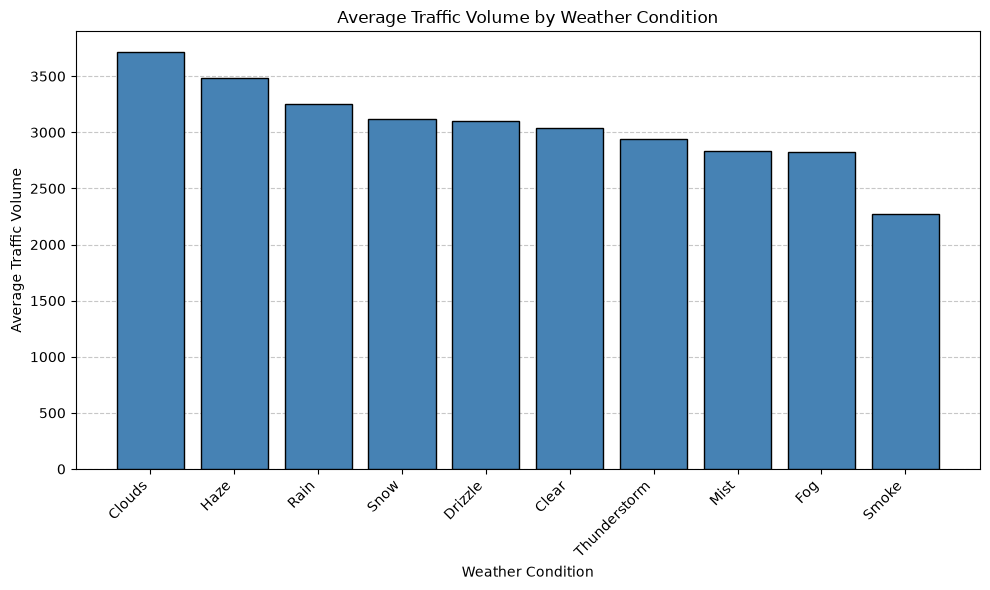

In [11]:
weather_counts = train_df.groupby("weather")["traffic_volume"].mean()

weather_counts = weather_counts.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))

ax.grid(axis="y", linestyle="--", alpha=0.7, zorder=0)

ax.bar(weather_counts.index, weather_counts.values, color="steelblue", edgecolor="black", zorder=3)

ax.set_xlabel("Weather Condition")
ax.set_ylabel("Average Traffic Volume")
ax.set_title("Average Traffic Volume by Weather Condition")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

Finding the range and percentage of decay on values:

In [12]:
max_weather_avg = weather_counts.max()
min_weather_avg = weather_counts.min()
difference_on_avg = max_weather_avg - min_weather_avg
perc_decay_avg = (difference_on_avg/max_weather_avg) * 100
print(f"Difference between max and min average = {difference_on_avg:.2f}")
print(f"Percentage of decay = {perc_decay_avg:.2f}")

Difference between max and min average = 1444.39
Percentage of decay = 38.89


> **Question:**
> 
> How did the visualization help in understanding the data?
> Which questions were answered and what hypothesis are left to be tested? 
> 
> Have you decided to remove some feature from the dataset? Why?

**Answer**: The visualization helped to understand which variables are the most and least influential on determining traffic volume by looking at how the traffic volume changes when the selected features change (answering question 5).<br>
First of all, on the first plot the traffic volume does decrease at nighttime compared to daytime, confirming the previous hypothesis. The minimum volume average represents a decrease of approx. 5312 compared to the maximum, or 93.3%, showing how important the time of the day variable is for determining the output.<br>
Regarding the second plot, the date doesn't seem influential on traffic, as no function-like behavior is present on the graph. The volume value floats around a constant near 3000, with random ups-and-downs which look like the independent from X, zero-mean error term $\epsilon$.<br>
Lastly, looking at the weather condition, just like the hour of the day plot, this feature exerts a clear influence on the traffic volume. Although we assumed earlier that a snowy condition would reduce the traffic, it shows up as the 4th greatest average on volume in a set of 10 different weathers, but other extreme ones do decrease it, like Thunderstorm. Comparing the greatest average (Clouds) to the smallest one (Smoke), there is a decay of around 1444 on the average traffic volume, or 38.9%. 

Therefore, the date is not a relevant feature to determine the traffic volume, as it is independent from this variable, so it should be removed. Moreover, the date a categorical and time-related variable, and the encoding we've seen to the moment is not capable of properly dealing with it, because every unique date would become a feature on one-hot encoding.

There is still one question left to answer: correlations between features.

----
### **Preprocessing**
(1.0 point) Now that you have a deeper insight about the problem, let's preprocess
the raw data with the necessary transformations and turn the data into an array,
ready to be fed into a model.

Create a function `preprocess_data` and make all required transformation, the
output must be a tuple (X, y) of numpy arrays, where X has shape (n_samples, n_features)
and y is a column array of shape (n_samples,).

Note that the distributions on the features in the test set may not coincide
with the ones in the train set, your preprocessing must take that into account
without peeking at test samples.

In [13]:
def preprocess_data(df: pd.DataFrame) -> tuple[NDArray[np.float64], NDArray[np.float64]]:
    # We're interested in 'hr' (X1), 'weather' (X2) and
    # traffic vol (Y). Every class of 'hr' and 'weather' becomes
    # its own feature (one-hot encoding), so 'hr' is expanded 
    # to 24 features and 'weather' to 10 features, totalizing:
    #   - n_samples = df.size
    #   - n_features = 34

    # Starting by defining each expected new feature to be present
    # in the array. This is important because the test might not have
    # all categories of each feature, but they need to be present in 
    # the final array.
    expected_hours = list(range(24))
    expected_weather = [
    'Rain', 'Clear', 'Clouds', 'Haze', 'Thunderstorm', 
    'Mist', 'Drizzle', 'Fog', 'Smoke', 'Snow'
    ]

    # Cast the columns as Categorical with the explicit categories. 
    # This way, if any category is not present on the dataframes, 
    # they are 
    df['hr'] = pd.Categorical(df['hr'], categories=expected_hours)
    df['weather'] = pd.Categorical(df['weather'], categories=expected_weather)

    # Using "get_dummies" Pandas function returns exactly what we
    # expect. Every category is a new feature on its own, with value
    # 0 or 1.
    one_hot_df = pd.get_dummies(df[['hr', 'weather']], dtype=int)

    # Converting to numpy 2D array
    X = one_hot_df.to_numpy()

    # Next, the labels (traffic_volume). This part is easier: just get
    # the column from the dataframe and convert it to numpy column
    # array.
    row_y = df['traffic_volume'].to_numpy()

    # As row_y is a 1D array, we need to add a new dimension to
    # convert it to a column array.
    y = row_y[:, np.newaxis]

    # Make sure the shape of each one is the expected:
    print("Shape of X (should be n_samples, 34):",
          np.shape(X))
    print("Shape of y (should be n_samples, 1):",
          np.shape(y))

    return (X, y)

---

## **Linear Regression**

Linear regression is a simple model that assumes a linear relationship between
the observed features and the target.
Specifically, given an observation $(x_1, x_2, \dots, x_n)$, we assume there exist
a set of weights $\beta_0, \beta_1, \beta_2, \dots, \beta_n$ such that

$$y \approx \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n.$$

Each weight $\beta_i$ measures the marginal contribution of $x_i$ to the
prediction while keeping other variables fixed.
The model assumes additive effects, meaning the influence of multiple variables
is the sum of their individual contributions unless interaction terms are
explicitly included.

For example, if raining decreases the traffic volume, but the morning rush hour
increases it, a rainy rush hour contribution is no different than the contribution
of rainy plus the contribution of the rush hour.

We can estimate the weights $\beta_i$ by measuring a discrepancy score between
predicted values $\hat{y}$ obtained with some weight $\beta$ and the ground-truth
value $y$, and minimizing this score.

A natural way to achieve this is by defining a distance between targets that is
differentiable. However, choosing a distance that is statistical relevant is not
trivial. Instead, we could measure what is the probability that, when given
a sample $x$ and a current weight $\beta$, the ground-truth $y$ is observed, *i.e.*

$$p(y \mid x, \beta).$$

This measures what is the probability of the ground-truth given that the model
with weights $\beta$ is the true estimator.

If we tweak the weights $\beta$ so that the probability of all ground-truths is
maximized, we obtain a well-fit model.
This is achieved by the likelihood function, under the assumption of independent
samples in the dataset.

$$\mathcal{L}(\beta) = \prod_{i=1}^n p(y^i \mid x^i, \beta).$$

Indicating that an estimator $\beta$ is only good if the ground-truth probabilities
are high across all the samples. As this criteria can be very small due to the
multiplication of small quantities, a common trick is to use the log likelihood
function instead, using the log properties,

$$\log \mathcal{L}(\beta) = \sum_{i=1}^n \log p(y^i \mid x^i, \beta),$$
and then minimizing $-\log \mathcal{L}(\beta)$.

This method is called Maximum Likelihood Estimation (MLE) and it is a very commonly
used estimator in Machine Learning, as we are going to see.

### **Gaussian assumption**
We cannot directly measure $p(y \mid x, \beta)$ at the moment, as we do not have
a probability distribution that links $y$ with $x$ and $\beta$ yet, but a
deterministic relationship (linear).

To introduce this probabilistic aspect, we can suppose that the approximation
between the ground-truth $y$ and the linear term $\hat{y} = \beta_0 + \beta_1 x_1 + \dots$
is only wrong by an unpredictable "error" $\epsilon$, also called a *residual*.
A common way of introducing this error is by supposing that $\epsilon$ comes from
a zero-centered normal (or Gaussian) distribution,
*i.e.* $\epsilon \sim \mathcal{N}(0, \sigma^2)$.

The relationship between $y$, $x$ and $\beta$ are now intermediated by $\epsilon$,

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n + \epsilon.$$

This makes $y$ to be a random variable centered at our linear predicition, deviated
by a random quantity, with fixed standard deviation $\sigma$ (homoscedastic).
This assumption is called **Gaussian assumption**, and has interesting properties
that intersect with the Ordinary Least Squares method, including the criterion.

With this assumption, we can measure $p(y \mid x, \beta)$ directly using the
Normal probability distribution function

$$p(y \mid x, \beta) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(- \frac{(y - x^T\beta)^2}{2\sigma^2}\right),$$

$$\log p(y \mid x, \beta) =  - \frac{(y - x^T\beta)^2}{2\sigma^2} - \log(\sqrt{2\pi\sigma^2}).$$

Thus, minimizing $-\log \mathcal{L}(\beta)$, yield to

$$-\log \mathcal{L}(\beta) \propto \sum_{i=1}^n (y^i - {x^i}^T\beta)^2 = \sum_{i=1}^n (y^i - \hat{y}^i)^2 $$

Which is equivalent to the Mean Squared Error (MSE) criterion.

### **Implementation**

(0.5 points) Under the statistical lens of Linear Regression, we have also
derived the same loss function as ordinary least squares method. Now it's time to
implement the `fit` method using **gradient descent** without using any machine
learning library.


Also, complete the following metric functions with their implementations and run
your model for different learning rates

In [14]:
def mse(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> float:
    # MSE: Mean Squared Error
    # Mean of squared differences between same-index true label 
    # and predicted label.
    return np.mean(np.square(y_true-y_pred))

def rss(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> float:
    # RSS: Residual Sum of Squares
    # Sum of squared differences between same-index true label
    # and predicted label. Necessary to calculate R^2 score.
    return np.sum(np.square(y_true-y_pred))

def tss(y_true: NDArray[np.float64]) -> float:
    # TSS: Total Sum of Squares
    # Sum of squared differences between true labels and
    # their mean. Necessary to calculate R^2 score.
    y_mean = np.mean(y_true)
    return np.sum(np.square(y_true-y_mean))

def r2_score(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> float:
    return 1 - (rss(y_true, y_pred)/tss(y_true))

def mae(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> float:
    # MAE: Mean Absolute Error
    # Mean of absolute differences between same-index true
    # label and predicted label. 
    return np.mean(np.abs(y_true-y_pred))

class LinearRegression:
    def __init__(
        self,
        learning_rate: float = 0.01,
        n_iterations: int = 1000,
    ) -> None:
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights: NDArray[np.float64] | None = None
        self.bias: float | None = None

    def fit(self, X: NDArray[np.float64], y: NDArray[np.float64]) -> None:
        n_samples, n_features = X.shape
        weights = np.zeros(n_features)
        bias = 0.0
        tolerance = 1e-5
        prev_cost = np.inf

        print("----------------------------------------")
        print("   Training linear regression model     ")
        print(f"  Learning rate = {self.learning_rate} ")
        print("----------------------------------------")

        # Gradient Descent loop, with a limit of n_iterations. 
        for i in range(self.n_iterations):
            # Current prediction and cost. Cost is based on MSE function. 
            y_pred = np.dot(X, weights) + bias
            curr_cost = mse(y, y_pred)

            # Print epoch and cost every 100 epochs to prevent output
            # flooding.
            if (i % 100 == 0):
                print(f"----- Current epoch: {i}... -----")
                print(f"Cost: {curr_cost}")

            # Stop criteria: when cost is smaller than tolerance (in this
            # case, set to 1e-5).
            if np.abs(prev_cost - curr_cost) < tolerance:
                print(f"Best weights found at epoch {i-1}")
                break

            prev_cost = curr_cost

            # Difference, needed to calculate the partial derivatives
            # to get the gradient
            diff = y_pred - y

            # Partial derivative of the MSE function for a weight 
            dw = (2 / n_samples) * np.dot(X.T, diff)

            # And for the bias
            db = (2 / n_samples) * np.sum(diff) 

            # Updating the weights and the bias value to the next iteration.
            weights = weights - self.learning_rate * dw
            bias = bias - self.learning_rate * db

        self.weights = weights
        self.bias = bias

        print("----------------------------------------")
        print(f"      Done training on epoch {i}       ")
        print("----------------------------------------")
        print("----- Best weights found: -----")
        print(f"Bias (w0) = {bias}")
        for i in range(n_features):
            print(f"w{i+1} = {weights[i]}")
        print("\n")

    
    def predict(self, X: NDArray[np.float64]) -> NDArray[np.float64]:
        assert self.weights is not None and self.bias is not None, "Model is not trained yet"
        
        y_pred = np.dot(X, self.weights) + self.bias
        return y_pred
        

In [15]:
def plot_results(var: list[float], performances: dict[str, list[float]], label: str, scale: str) -> None:
    n_metrics = len(performances)

    fig, ax = plt.subplots(figsize=(5 * n_metrics, 5), ncols=n_metrics)

    for i, (metric_name, metric_values) in enumerate(performances.items()):
        ax[i].plot(var, metric_values, marker="o")
        ax[i].set_xlabel(label)
        ax[i].set_title(metric_name)
        ax[i].grid()
    
        ax[i].set_xscale(scale)

    plt.tight_layout()
    plt.show()


Shape of X (should be n_samples, 34): (21341, 34)
Shape of y (should be n_samples, 1): (21341, 1)
----------------------------------------
   Training linear regression model     
  Learning rate = 0.1 
----------------------------------------
----- Current epoch: 0... -----
Cost: 14601812.343892038
----- Current epoch: 100... -----
Cost: 1416072.4381668079
----- Current epoch: 200... -----
Cost: 952778.0987846737
----- Current epoch: 300... -----
Cost: 859769.5268053686
----- Current epoch: 400... -----
Cost: 840659.3221147052
----- Current epoch: 500... -----
Cost: 836513.7287488126
----- Current epoch: 600... -----
Cost: 835484.4644824307
----- Current epoch: 700... -----
Cost: 835148.8047825476
----- Current epoch: 800... -----
Cost: 834993.1607975765
----- Current epoch: 900... -----
Cost: 834899.222707623
----------------------------------------
      Done training on epoch 999       
----------------------------------------
----- Best weights found: -----
Bias (w0) = 2840.359534

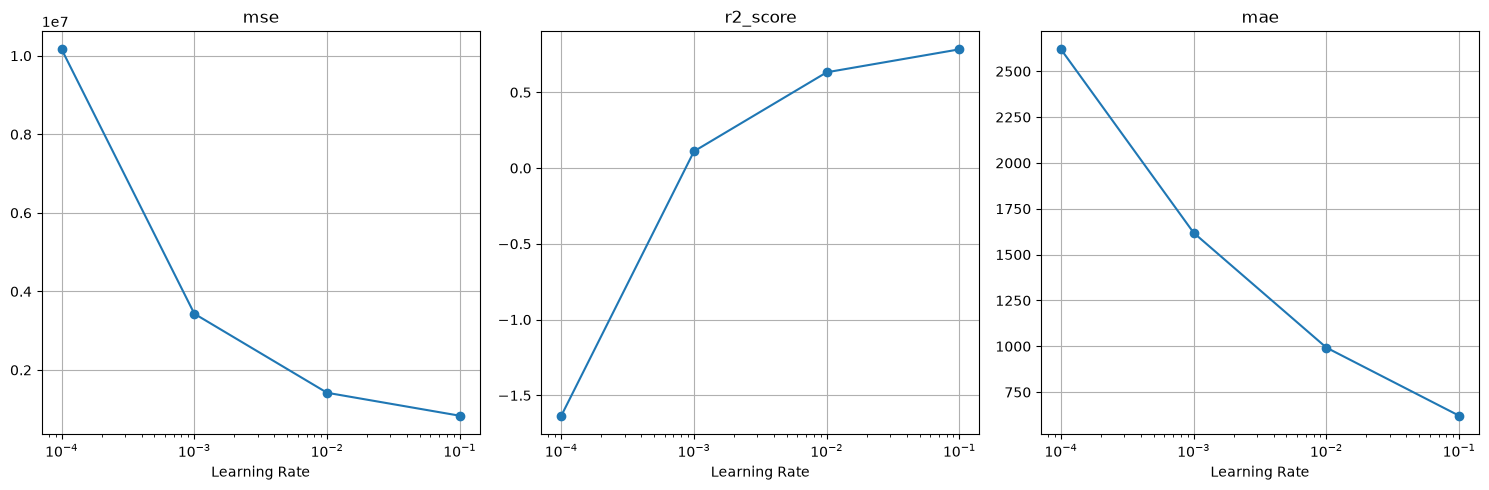

In [16]:
X, y = preprocess_data(train_df)

# You can experiment with a pre-defined set of learning rates or
# with a range of learning rates (e.g. logarithmically spaced)
lrs = [0.1, 0.01, 0.001, 0.0001]

y = y.reshape(-1)

performances = {
    "mse": [],
    "r2_score": [],
    "mae": [],
    # Add other metrics here if you implemented them
}

for lr in lrs:
    model = LinearRegression(learning_rate=lr, n_iterations=1000)
    model.fit(X, y)
    y_pred = model.predict(X)

    mse_score = mse(y, y_pred)
    r2 = r2_score(y, y_pred)
    mae_score = mae(y, y_pred)

    performances["mse"].append(mse_score)
    performances["r2_score"].append(r2)
    performances["mae"].append(mae_score)

plot_results(lrs, performances, "Learning Rate", "log")

> **Question:**
>
> How did the model perform for different learning rates?
> What happened when the learning rate was too small or too large?
>
> Interpret the metric values obtained.
Is the prediction error small relative to the scale of the target variable?
>
> Propose at least one hypothesis explaining the observed error.

**Answers**:
The model performed worse as the learning rate logarithimically decreases, as we can see in the MSE and MAE plots, relative to error. The smaller the learning rate, more error-prone the model is, as the predictions are too far from the real label. Looking at the R<sup>2</sup> score, which measures how well the model fit the data (the closer to 1, the better), the largest score was obtained from LR = 0.1, where it was around 0.7. <br>

The MAE, which is the mean error of all differences between the predicted and real values is relatively high even for the minimum one, achieved when LR = 0.1. Let's look how relatively big it is to the mean value of traffic volume in the training dataset:

In [42]:
print(f"Relative error: {np.min(performances["mae"]/np.mean(y))}")

Relative error: 0.1876427594987543


The error corresponds to around 19% of the target variable mean, a substantial error when trying to predict it.

An hypothesis on why the error metrics increase as the learning rate decreases, which theoretically should prevent overshooting, is that the target variable scale is too big compared to the gradient descent algorithm weight and bias adjustments, so it never reaches the minimum of the cost function. This behaviour can be seen on the output cell of the training: the loop reaches the `n_iterations` value for every learning rate. This could be fixed by scaling the traffic volume variable. Let's try that and see if the performance improves. 

Determining a new pre-processing function, adding a normalization by mean part:

In [18]:
def preprocess_data(df: pd.DataFrame) -> tuple[NDArray[np.float64], NDArray[np.float64]]:
    # We're interested in 'hr' (X1), 'weather' (X2) and
    # traffic vol (Y). Every class of 'hr' and 'weather' becomes
    # its own feature (one-hot encoding), so 'hr' is expanded 
    # to 24 features and 'weather' to 10 features, totalizing:
    #   - n_samples = df.size
    #   - n_features = 34

    # Starting by defining each expected new feature to be present
    # in the array. This is important because the test might not have
    # all categories of each feature, but they need to be present in 
    # the final array.
    expected_hours = list(range(24))
    expected_weather = [
    'Rain', 'Clear', 'Clouds', 'Haze', 'Thunderstorm', 
    'Mist', 'Drizzle', 'Fog', 'Smoke', 'Snow'
    ]

    # Cast the columns as Categorical with the explicit categories. 
    # This way, if any category is not present on the dataframes, 
    # they are 
    df['hr'] = pd.Categorical(df['hr'], categories=expected_hours)
    df['weather'] = pd.Categorical(df['weather'], categories=expected_weather)

    # Using "get_dummies" Pandas function returns exactly what we
    # expect. Every category is a new feature on its own, with value
    # 0 or 1.
    one_hot_df = pd.get_dummies(df[['hr', 'weather']], dtype=int)

    # Converting to numpy 2D array
    X = one_hot_df.to_numpy()

    # Next, the labels (traffic_volume). This part is easier: just get
    # the column from the dataframe and convert it to numpy column
    # array.
    row_y = df['traffic_volume'].to_numpy()

    # As row_y is a 1D array, we need to add a new dimension to
    # convert it to a column array.
    y = row_y[:, np.newaxis]

    # REFACTORING: adding mean normalization to the function, in order
    # to scale the y variable.
    y = (y - np.mean(y))/np.max(y)

    # Make sure the shape of each one is the expected:
    print("Shape of X (should be n_samples, 34):",
          np.shape(X))
    print("Shape of y (should be n_samples,):",
          np.shape(y))

    return (X, y)

Now, running the model fit and predict again:

Shape of X (should be n_samples, 34): (21341, 34)
Shape of y (should be n_samples,): (21341, 1)
----------------------------------------
   Training linear regression model     
  Learning rate = 0.1 
----------------------------------------
----- Current epoch: 0... -----
Cost: 0.0727979328154638
----- Current epoch: 100... -----
Cost: 0.026544383073595218
----- Current epoch: 200... -----
Cost: 0.017915903642748036
Best weights found at epoch 277
----------------------------------------
      Done training on epoch 278       
----------------------------------------
----- Best weights found: -----
Bias (w0) = -0.0025537519196088326
w1 = -0.30026973671838003
w2 = -0.3389333683995579
w3 = -0.3544449586003825
w4 = -0.356692682893263
w5 = -0.3163587477806995
w6 = -0.14013148059353617
w7 = 0.11359347088835514
w8 = 0.18196221113912475
w9 = 0.1568672234287003
w10 = 0.13221106122122137
w11 = 0.1122406287364654
w12 = 0.1451608228297975
w13 = 0.17493301959209043
w14 = 0.17187883004108429
w15 =

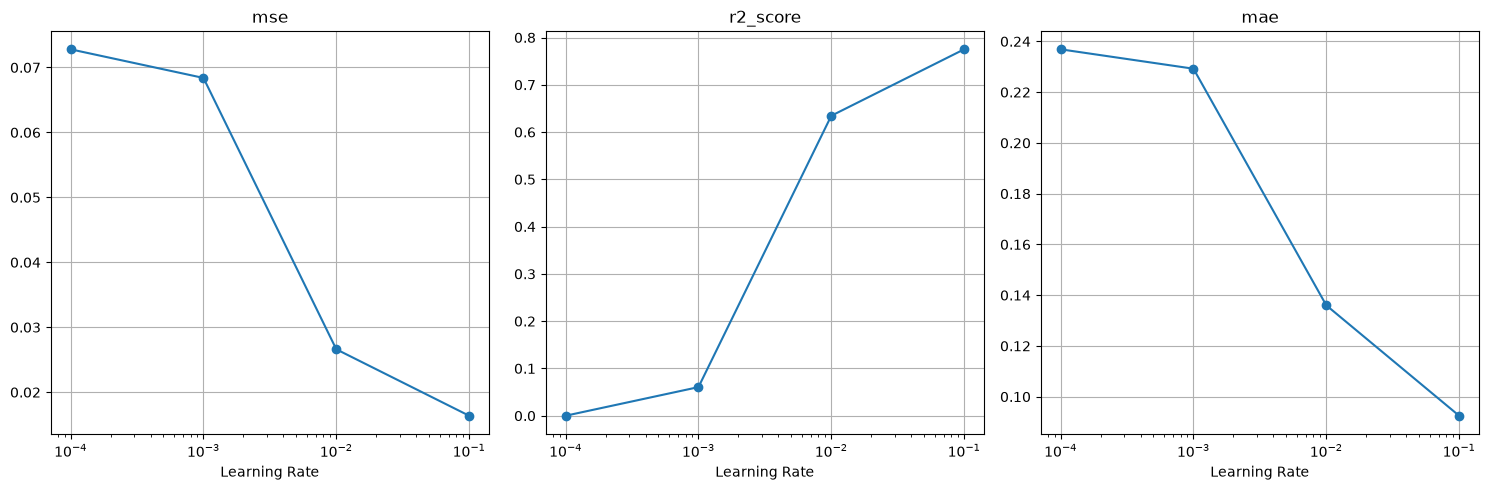

In [19]:
X, y = preprocess_data(train_df)

# You can experiment with a pre-defined set of learning rates or
# with a range of learning rates (e.g. logarithmically spaced)
lrs = [0.1, 0.01, 0.001, 0.0001]

y = y.reshape(-1)

performances = {
    "mse": [],
    "r2_score": [],
    "mae": [],
    # Add other metrics here if you implemented them
}

for lr in lrs:
    model = LinearRegression(learning_rate=lr, n_iterations=1000)
    model.fit(X, y)
    y_pred = model.predict(X)

    mse_score = mse(y, y_pred)
    r2 = r2_score(y, y_pred)
    mae_score = mae(y, y_pred)

    performances["mse"].append(mse_score)
    performances["r2_score"].append(r2)
    performances["mae"].append(mae_score)

plot_results(lrs, performances, "Learning Rate", "log")

The performance of the model has improved for lower than 0.1 learning rates, and the performance for LR = 0.1 is slightly better, too. They still have lower R<sup>2</sup> score and higher error metrics than 0.1. A hint comes from the output, again: some are hitting the iteration limit and some are converging earlier than necessary (the difference between consecutive iterations costs are lower than the tolerance, set as 1e-5). Using a higher iteration limit (e.g. 50000) and lowering the tolerance (to 1e-6 or 1e-7, for example) might help. The best observed learning rate is 0.1.

---
### **Visualizing Predictions**

(1.0 points) Numerical metrics summarize model quality, but visual diagnostics reveal structural problems that scalar measures may hide. Two standard visual tools are the predicted vs. observed plot and the Q–Q plot of residuals.

Choose a model from the previous session to analyse further here.

#### **Predicted vs. Observed Plot**

A direct way to evaluate prediction quality is to compare the predicted values with the true observations.
For each sample, plot the pair `(y, y_pred)`, the ideal predictor would have
perfectly match predictions, yielding all points in the line y = x in the graph.

However, this is often not the case, as prediction can go wrong.
This plot help us interpret points that are closer to the x=y line as better
predictions, and points further from this line as bad predictions.

If the overall shape of the points does not follow the line, we may have a
**systematic error**, indicating model misspecification.

By coloring each point by some other characteristic, we can also see if the error
is systematic with respect to that characteristic.
For example, the model mispredicts some seasons more than others.

You can explore more plots to get an insight on why and how is your model fit.

In [20]:
def pred_vs_true_plot(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> None:
    _, ax = plt.subplots(figsize=(10, 6))

    ax.grid()
    ax.scatter(y_true, y_pred, alpha=0.5)
    ax.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], color='red', linestyle='--', label='Ideal Fit')
    ax.set_xlabel("True Values")
    ax.set_ylabel("Predicted Values")
    ax.set_title("Predicted vs True Values")
    ax.legend()
    plt.show()

----------------------------------------
   Training linear regression model     
  Learning rate = 0.1 
----------------------------------------
----- Current epoch: 0... -----
Cost: 0.0727979328154638
----- Current epoch: 100... -----
Cost: 0.026544383073595218
----- Current epoch: 200... -----
Cost: 0.017915903642748036
Best weights found at epoch 277
----------------------------------------
      Done training on epoch 278       
----------------------------------------
----- Best weights found: -----
Bias (w0) = -0.0025537519196088326
w1 = -0.30026973671838003
w2 = -0.3389333683995579
w3 = -0.3544449586003825
w4 = -0.356692682893263
w5 = -0.3163587477806995
w6 = -0.14013148059353617
w7 = 0.11359347088835514
w8 = 0.18196221113912475
w9 = 0.1568672234287003
w10 = 0.13221106122122137
w11 = 0.1122406287364654
w12 = 0.1451608228297975
w13 = 0.17493301959209043
w14 = 0.17187883004108429
w15 = 0.1973215668129673
w16 = 0.23183703418398444
w17 = 0.29445395870507446
w18 = 0.2480074629449484

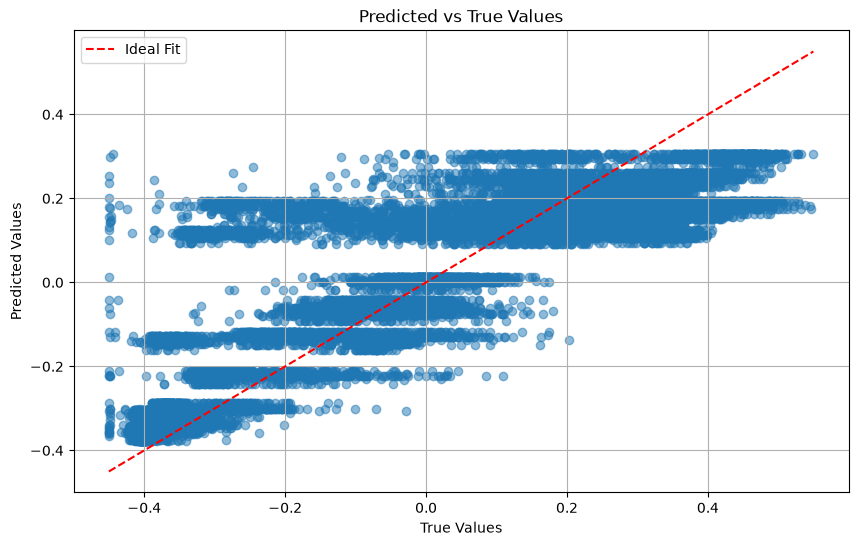

In [21]:
best_lr = 0.1 # Choose the best learning rate based on the previous graphs

best_linear_model = LinearRegression(learning_rate=best_lr, n_iterations=10000)
best_linear_model.fit(X, y)
y_pred = best_linear_model.predict(X)

pred_vs_true_plot(y, y_pred)

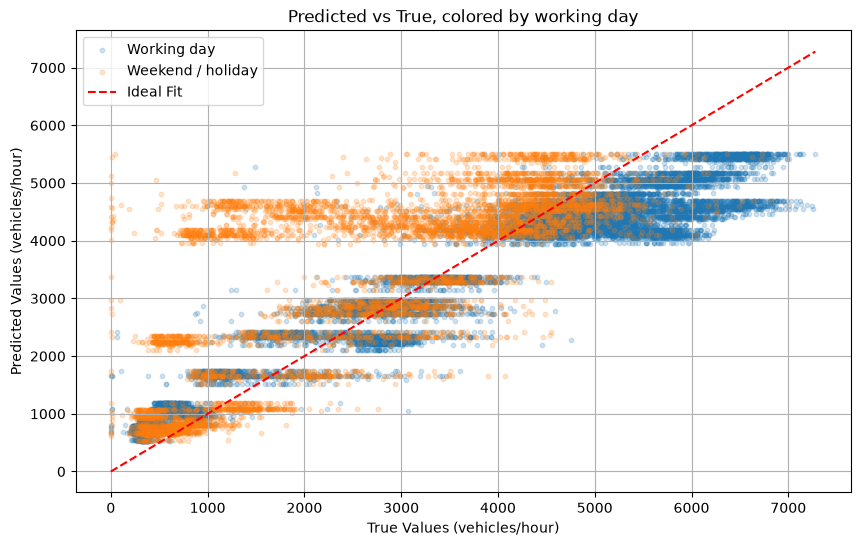

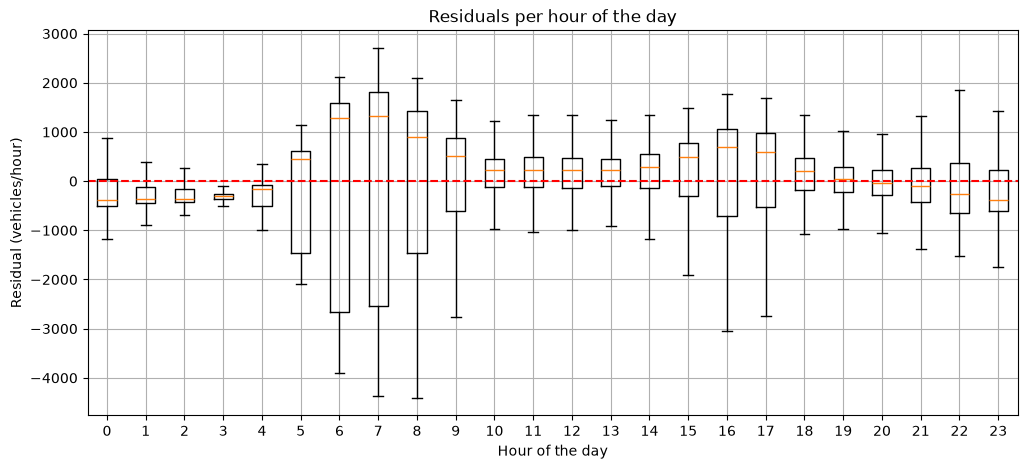

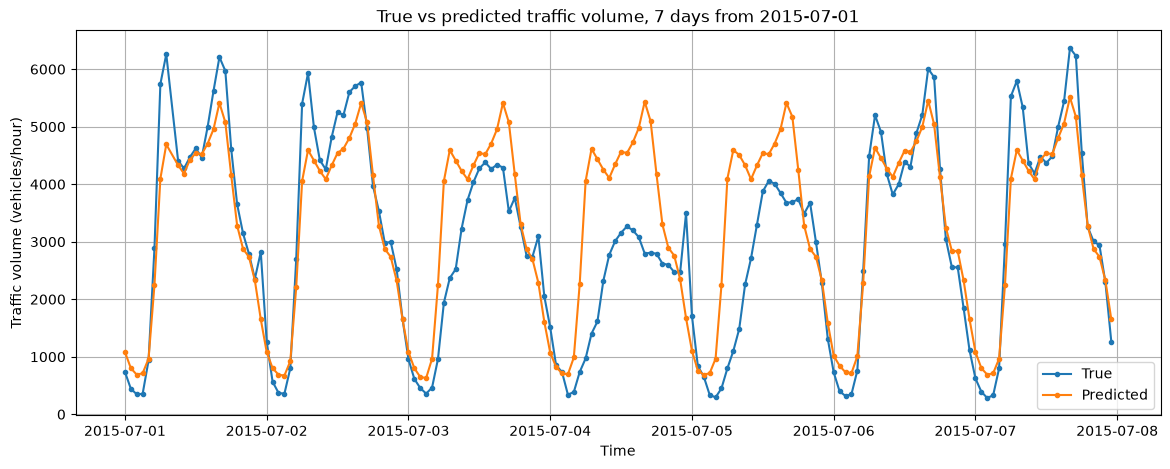

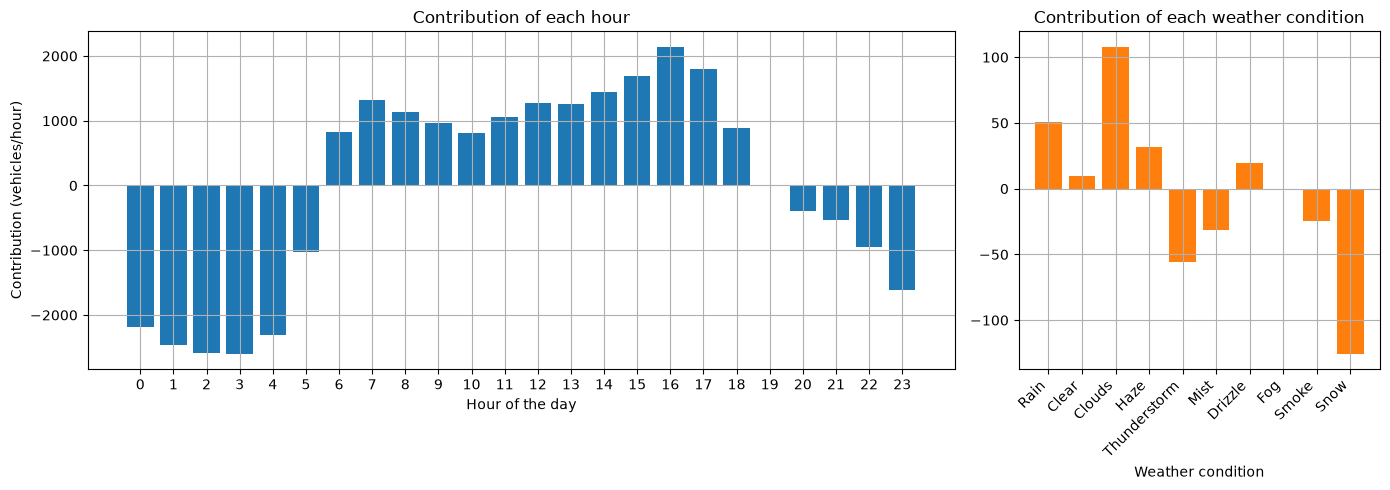

Number of training samples: 21341
Number of distinct predicted values: 221


In [22]:
# Explore more plots to analyze the predictions, e.g., predictions vs time, contribution of each feature to the predictions, etc.

# The target was mean-normalized inside preprocess_data, so both y and
# y_pred are in normalized units. To read the plots in "vehicles per
# hour" we invert that transformation with the training statistics.
y_mean_train = train_df["traffic_volume"].mean()
y_max_train = train_df["traffic_volume"].max()
def to_vehicles(y_norm: NDArray[np.float64]) -> NDArray[np.float64]:
    return y_norm * y_max_train + y_mean_train

# Auxiliary arrays taken from the training dataframe.
# They are only used for coloring/grouping the plots.
hours = np.asarray(train_df["hr"]).astype(int)
is_workingday = train_df["workingday"].to_numpy().astype(bool)

y_true_veh = to_vehicles(y)
y_pred_veh = to_vehicles(y_pred)
residuals_veh = y_true_veh - y_pred_veh


def pred_vs_true_by_group(
    y_true: NDArray[np.float64],
    y_pred: NDArray[np.float64],
    group: NDArray[np.bool_],
) -> None:
    # Same predicted vs true plot as before, but coloring each point by
    # whether it is a working day. If the errors are systematic with
    # respect to this feature, the two colors will occupy different
    # regions of the plot.
    _, ax = plt.subplots(figsize=(10, 6))

    ax.grid()
    ax.scatter(y_true[group], y_pred[group], alpha=0.2, s=10,
               label="Working day")
    ax.scatter(y_true[~group], y_pred[~group], alpha=0.2, s=10,
               label="Weekend / holiday")

    limits = [y_true.min(), y_true.max()]
    ax.plot(limits, limits, color="red", linestyle="--", label="Ideal Fit")

    ax.set_xlabel("True Values (vehicles/hour)")
    ax.set_ylabel("Predicted Values (vehicles/hour)")
    ax.set_title("Predicted vs True, colored by working day")
    ax.legend()
    plt.show()


def residuals_by_hour(residuals: NDArray[np.float64],
                      hours: NDArray[np.int64]) -> None:
    # A boxplot of the residuals for each hour of the day. If the model
    # were well specified, every box would be centered at zero with a
    # similar spread.
    _, ax = plt.subplots(figsize=(12, 5))

    ax.grid()
    ax.boxplot([residuals[hours == h] for h in range(24)],
               positions=range(24), showfliers=False)
    ax.axhline(0, color="red", linestyle="--")

    ax.set_xlabel("Hour of the day")
    ax.set_ylabel("Residual (vehicles/hour)")
    ax.set_title("Residuals per hour of the day")
    plt.show()


def predictions_vs_time(y_true: NDArray[np.float64],
                        y_pred: NDArray[np.float64],
                        n_days: int = 7) -> None:
    # Predictions and ground-truth along time, so we can see whether the
    # model reproduces the daily cycle.
    timestamps = pd.DatetimeIndex(train_df["date"].to_numpy()
                                  + pd.to_timedelta(hours, unit="h"))
    order = np.argsort(timestamps)
    timestamps = timestamps[order]

    # The record is not perfectly regular (some hours were never
    # reported, and the first weeks have only a couple of samples per
    # day), so we look for the first sequence of n_days consecutive days
    # with nearly complete hourly coverage. Otherwise the plot would be
    # mostly straight lines connecting distant points.
    samples_per_day = pd.Series(timestamps.normalize()).value_counts().sort_index()
    complete_days = samples_per_day[samples_per_day >= 20].index

    start = complete_days[0]
    for i in range(len(complete_days) - n_days + 1):
        if (complete_days[i + n_days - 1] - complete_days[i]).days == n_days - 1:
            start = complete_days[i]
            break

    window = ((timestamps >= start)
              & (timestamps < start + pd.Timedelta(days=n_days)))

    _, ax = plt.subplots(figsize=(14, 5))

    ax.grid()
    ax.plot(timestamps[window], y_true[order][window],
            marker="o", markersize=3, label="True")
    ax.plot(timestamps[window], y_pred[order][window],
            marker=".", label="Predicted")

    ax.set_xlabel("Time")
    ax.set_ylabel("Traffic volume (vehicles/hour)")
    ax.set_title(f"True vs predicted traffic volume, {n_days} days from "
                 f"{start.date()}")
    ax.legend()
    plt.show()


def feature_contributions(model: LinearRegression) -> None:
    # Contribution of each one-hot feature to the prediction, in
    # vehicles/hour. Because the features are one-hot encoded, every
    # prediction is simply bias + (hour weight) + (weather weight).
    hour_names = list(train_df["hr"].cat.categories)
    weather_names = list(train_df["weather"].cat.categories)

    # The weights were learned on the normalized target, so we scale
    # them back to vehicles/hour.
    weights_veh = model.weights * y_max_train

    _, ax = plt.subplots(figsize=(14, 5), ncols=2,
                         width_ratios=[len(hour_names), len(weather_names)])

    ax[0].grid()
    ax[0].bar(range(len(hour_names)), weights_veh[:len(hour_names)])
    ax[0].set_xticks(range(len(hour_names)), hour_names)
    ax[0].set_xlabel("Hour of the day")
    ax[0].set_ylabel("Contribution (vehicles/hour)")
    ax[0].set_title("Contribution of each hour")

    ax[1].grid()
    ax[1].bar(range(len(weather_names)), weights_veh[len(hour_names):],
              color="tab:orange")
    ax[1].set_xticks(range(len(weather_names)), weather_names, rotation=45,
                     ha="right")
    ax[1].set_xlabel("Weather condition")
    ax[1].set_title("Contribution of each weather condition")

    plt.tight_layout()
    plt.show()


pred_vs_true_by_group(y_true_veh, y_pred_veh, is_workingday)
residuals_by_hour(residuals_veh, hours)
predictions_vs_time(y_true_veh, y_pred_veh)
feature_contributions(best_linear_model)

# How many different values can this model actually output? Every
# prediction is bias + (one hour weight) + (one weather weight), so the
# model is restricted to a small, finite set of answers.
print("Number of training samples:", len(y_pred))
print("Number of distinct predicted values:",
      len(np.unique(np.round(y_pred, 6))))


> **Question:**
>
> Based on your visualizations, do you observe systematic deviations
(for example curvature or clusters)?
>
> If systematic patterns exist, what do they suggest about the relationship between
the predictors and the target?
>
> Does this visualization support or contradict the hypotheses you proposed earlier?

**Answers**:
Based on the visualizations above, we can observe clear horizontal stripes in the `Predicted vs True` plot instead of a cloud around the diagonal y = x, as we would ideally expected. This systematic pattern indicates that the model can predict just a limited values of different predictions, despite the large variation in the true traffic volumes.</br>
When we consider this result together with the `Residuals per hour of the day` and `Contribution of each feature` plots, we can see that the model captures general effect of daily traffic, but the available predictors are insufficient to understand all the variation in the target. In particular, the `Contribution of each feature` plot shows that the hour of the day has a much stronger effect on the model's predictions than the weather condition (hour contributes ~2000 vehicles/h at most, meanwhile weather contributes ~100 vehicles/h).</br>
This suggests that the predictors used in the model oversimplify the inference problem. As shown in the `True vs predicted traffic volume` plot, the predicted line follow a clearly periodic pattern based on the hour of the day with slightly deviations in case of different weathers, while the true traffic volume presents huge variations that cannot be explained by the chosen predictors.</br>
One important reason for these limitations is the selection of features. With 24 hours and 10 weather categories, there are only 240 possible hour-weather combinations. Therefore, observations with the same hour and weather conditions receive the same prediction, even when their actual traffic volumes are very different. In the above plots we can se that the number of distinct predicted values is 221, pretty close to the maximum reachable with this set os features.</br>
Therefore, the visualizations support some of our earlier hypotheses, mainly the strong relationship between the hour of the day and the traffic volume. However, the predictors are undoubtedly useful for capturing the general pattern of traffic volume, but they are  not sufficient to describe the full complexity of the relationship between the predictors and the target.

---
#### **Residual Analysis**
(1.0 points) As discussed above, a main assumption we have made is the nature of $\epsilon$ to
be Gaussian.

These error values are now computable by the difference between the ground-truth and
the predicted values

$$r_i = y - \hat{y} \sim \mathcal{N}(0, \sigma)$$

Therefore, if our linear regression model is correct, we can observe normally
distributed residuals across the dataset.
One way of checking how normally is distributed our distribution is by a
quantile–quantile (Q–Q) plot.

This plot compares the empirical distribution of residuals with the theoretical quantiles of a reference distribution (usually the normal distribution).

To do this, we sort the residuals, compute the theoretical quantiles and plot they along
so each point (r_i, q_i) compares the observed residual and the quantile if the
distribution were normally distributed.

Similarly to the previous plot, if the points follow the line y=x, the quantiles
are well aligned with the empirical distribution, suggesting a good fit.
However, curvatures may represent skews in the distribution, usually indicating
that the distribution is not normal.

In [23]:
def q_q_plot(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> None:
    residuals = y_true - y_pred

    sorted_residuals = np.sort(residuals)
    theoretical_quantiles = np.sort(np.random.normal(loc=0, scale=np.std(residuals), size=len(residuals)))

    plt.figure(figsize=(10, 6))
    plt.grid()
    plt.scatter(theoretical_quantiles, sorted_residuals, alpha=0.5, s=10, label='Residuals')
    plt.plot([theoretical_quantiles.min(), theoretical_quantiles.max()], [theoretical_quantiles.min(), theoretical_quantiles.max()], color='red', linestyle='--', label='Ideal Fit')
    plt.xlabel("Theoretical Quantiles")
    plt.ylabel("Ordered Residuals")
    plt.title("Q-Q Plot of Residuals")
    plt.legend()
    plt.show()

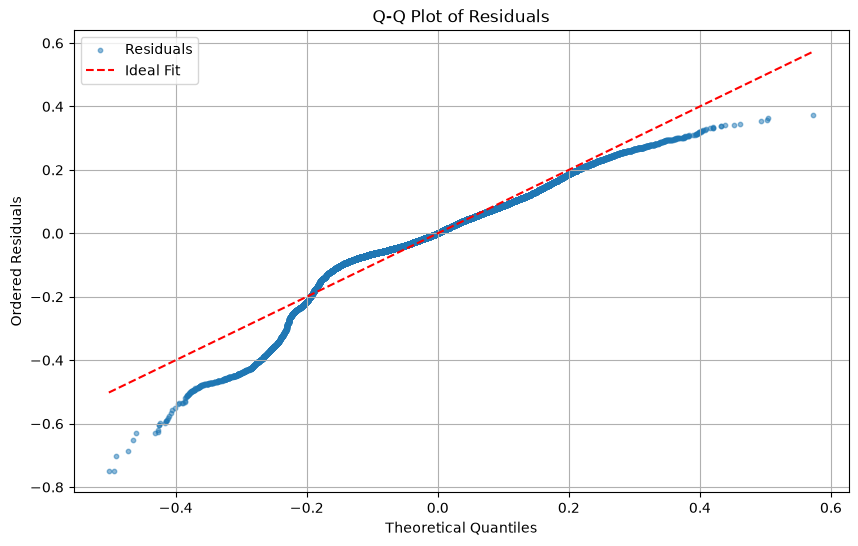

In [24]:
q_q_plot(y, y_pred)

> **Question:**
>
> Are the points approximately aligned along a straight line?
>
> What does this indicate about the Gaussian noise assumption used to derive
the MSE objective?
> 
> Based on the evidence from the metrics and plots,
> is linear regression an appropriate model for this dataset?
>
> Justify your conclusion.

**Answers**:
The points are approximately aligned along the diagonal y = x in the central part of the plot, with some deviations mainly at the beginning and the end.</br>
This indicates that the Gaussian noise assumption is not completely accurate, since the points deviate from the ideal fit, especially at the endpoints. So, the residuals don't perfectly follow a normal distribution.</br>
Based on the evidence from the past metrics and plots, linear regression is a reasonable model for this dataset, but it's not able to capture all the complexity of the problem. The residual analysis and the previous visualizations show systematic patterns that the model cannot fully explain. A possible way to improve the accuracy of our model would be to include more relevant variables and consider other types of relationships between the predictors and the target to enhance model's performance.

---

## **Polynomial Models**


Linear regression assumes that the relationship between the features and the
target is linear.
However, in many real-world situations the relationship between
a variable and the output may be curved or more complex.

For example, suppose that the traffic volume grows as the temperature rises from
a freezing morning up to a comfortable level, but then stops growing (or even
decreases) once the weather becomes too hot.
A straight line would not be able to capture this behavior.

One way to increase the flexibility of linear regression is to transform the
input features.
Instead of using raw variables $x_i$, we can include higher
powers of it, creating new features such as $x_i^2$, $x_i \cdot x_j$, and so on.

For instance, a quadratic model can be written as

$$y \approx \beta_0 + \beta_1 x + \beta_2 x^2.$$

Although this model is nonlinear with respect to the original variables,
it is still **linear in the parameters** $\beta$.
Because of this, the same training methods used for linear regression can still
be applied.

The effect is an increased set of possible models that can describe the relationship
between $x$ and $y$ via parameters $\beta$.

In practice, polynomial regression is implemented by **expanding the feature
space**.
For example, if the original input is $(x_1, x_2)$, a polynomial expansion of
degree two could produce the new feature vector

$$(x_1, x_2, x_1^2, x_2^2, x_1 x_2).$$

The regression model is then applied to this expanded set of features.
This transformation allows the model to capture nonlinear relationships while
keeping the optimization problem simple.

### **Model Capacity and Overfitting**

Increasing the polynomial degree increases the **capacity** of the model. A
higher-degree polynomial can represent more complex relationships in the data.

However, a model that is too flexible may start fitting the noise present in
the training data instead of the underlying relationship. This phenomenon is
called **overfitting**.

As the polynomial degree increases:

- The training error usually decreases.
- The test error may start increasing after a certain point.

This happens because the model becomes too specialized to the training dataset.

### **Implementation**

(1.0 points) Implement the `polynomial_expansion` function that expands the input features
to polynomial features of degree at most $d$.

Instead of using only the original variables, now include polynomial terms with
different degree values, for example, $d = 2, 3, \dots$.
This makes the model more flexible and can represent non-linear relationships
between the predictors and the target.

Remember to test for different learning rates, similar to what was done previously.

In [25]:
def polynomial_expansion(X: NDArray[np.float64], d: int) -> NDArray[np.float64]:
    from itertools import combinations_with_replacement

    _, n_features = X.shape

    expansion = []

    for degree in range(1, d+1):
        for index in combinations_with_replacement(range(n_features), degree):
            new_feature = np.prod(X[:, index], axis=1)
            expansion.append(new_feature)

    print(f"{len(expansion)-n_features} new features has been generated")

    return np.column_stack(expansion)

0 new features has been generated
----------------------------------------
   Training linear regression model     
  Learning rate = 0.1 
----------------------------------------
----- Current epoch: 0... -----
Cost: 0.0727979328154638
----- Current epoch: 100... -----
Cost: 0.026544383073595218
----- Current epoch: 200... -----
Cost: 0.017915903642748036
Best weights found at epoch 277
----------------------------------------
      Done training on epoch 278       
----------------------------------------
----- Best weights found: -----
Bias (w0) = -0.0025537519196088382
w1 = -0.30026973671838003
w2 = -0.3389333683995579
w3 = -0.3544449586003825
w4 = -0.35669268289326295
w5 = -0.3163587477806995
w6 = -0.14013148059353617
w7 = 0.11359347088835516
w8 = 0.18196221113912472
w9 = 0.1568672234287003
w10 = 0.13221106122122134
w11 = 0.11224062873646541
w12 = 0.1451608228297975
w13 = 0.17493301959209046
w14 = 0.17187883004108429
w15 = 0.1973215668129673
w16 = 0.23183703418398444
w17 = 0.29445

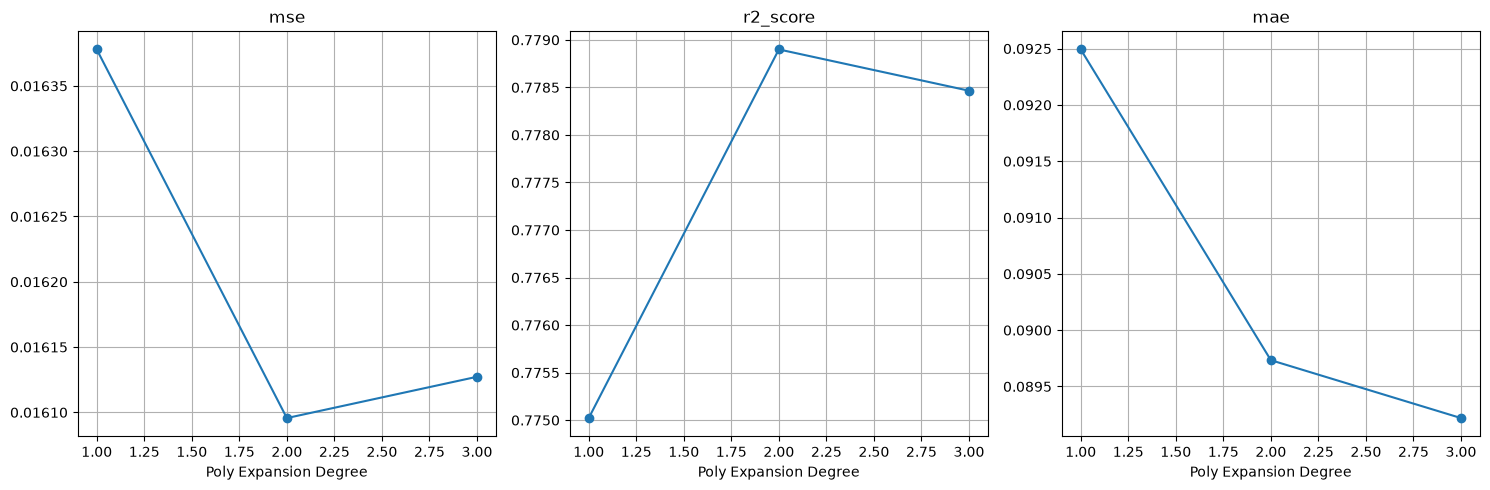

In [26]:
# Implement and train the polynomial regression models here using the 
# polynomial_expansion function to transform the features before training the linear regression model.

# Experiment with different degrees and analyze the results to choose the best combination
# of learning rate and degree for the polynomial regression model.

performances = {
    "mse": [],
    "r2_score": [],
    "mae": [],
    # Add other metrics here if you implemented them
}

degrees = [1, 2, 3]
for d in degrees:
    model = LinearRegression(learning_rate=0.1, n_iterations=10000)
    X_poly = polynomial_expansion(X, d)
    model.fit(X_poly, y)
    y_pred = model.predict(X_poly)

    mse_score = mse(y, y_pred)
    r2 = r2_score(y, y_pred)
    mae_score = mae(y, y_pred)

    performances["mse"].append(mse_score)
    performances["r2_score"].append(r2)
    performances["mae"].append(mae_score)


plot_results(degrees, performances, "Poly Expansion Degree", "linear")

> **Question:**
> 
> How does the training error of the polynomial model compare with the
training error of the linear regression model?
>
> Does this result indicate that it is better than the linear
model for this problem?
>
> Which degree would you select to explore?

**Answers**:
The training error (MSE and MAE) of the polynomial model compared with linear model is slightly smaller, leading to a slightly higher R² score. We tested the degrees 1 (linear), 2 and 3 (polynomials), and degree 2 showed the best results, followed by degree 3 and then degree 1.</br>
This result doesn't necessarily indicate that the polynomial model is better than linear model, it indicates that the polynomial is fitting the training data better. We need to measure the error on the test data to ensure that overfitting isn't occurring in this case.
For now, based on the evidences shown above, we would select degree 2 to explore.

---
### **Visualizing Predictions**

(1.5 points) Inspect the predicted vs observed plot, compare with the same plots used in the
linear model, are they different?

Explore how the results change and link them with training error in the polynomial
model.

595 new features has been generated
----------------------------------------
   Training linear regression model     
  Learning rate = 0.1 
----------------------------------------
----- Current epoch: 0... -----
Cost: 0.0727979328154638
----- Current epoch: 100... -----
Cost: 0.0172414470667806
Best weights found at epoch 146
----------------------------------------
      Done training on epoch 147       
----------------------------------------
----- Best weights found: -----
Bias (w0) = -0.0029958365059218617
w1 = -0.13824870565662997
w2 = -0.15683567772651436
w3 = -0.16463556294946755
w4 = -0.16597107927470373
w5 = -0.14643805249200367
w6 = -0.06482698666855599
w7 = 0.05313895286119782
w8 = 0.08556312459951615
w9 = 0.07370853455060636
w10 = 0.06207979754203376
w11 = 0.05215211376550703
w12 = 0.06721854215443576
w13 = 0.0804174809534676
w14 = 0.07903027149711597
w15 = 0.09034131868824036
w16 = 0.10633415909389013
w17 = 0.13425330662225782
w18 = 0.11358057524559763
w19 = 0.055522772

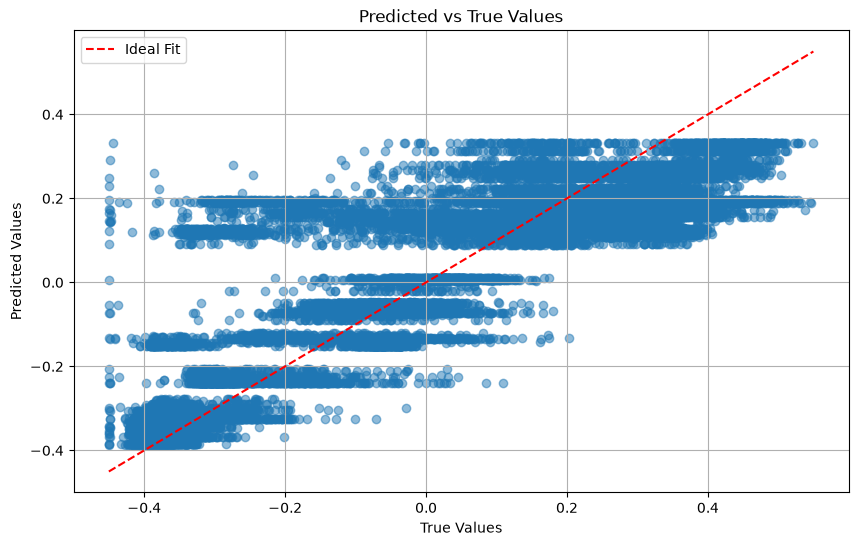

In [27]:
best_lr = 0.1 # Choose the best learning rate based on the previous graphs
best_degree = 2 # Choose the best degree based on experimentation with different degrees and analyzing the results

X_poly = polynomial_expansion(X, best_degree)

best_poly_model = LinearRegression(learning_rate=best_lr, n_iterations=1000)
best_poly_model.fit(X_poly, y)
y_pred = best_poly_model.predict(X_poly)

pred_vs_true_plot(y, y_pred)

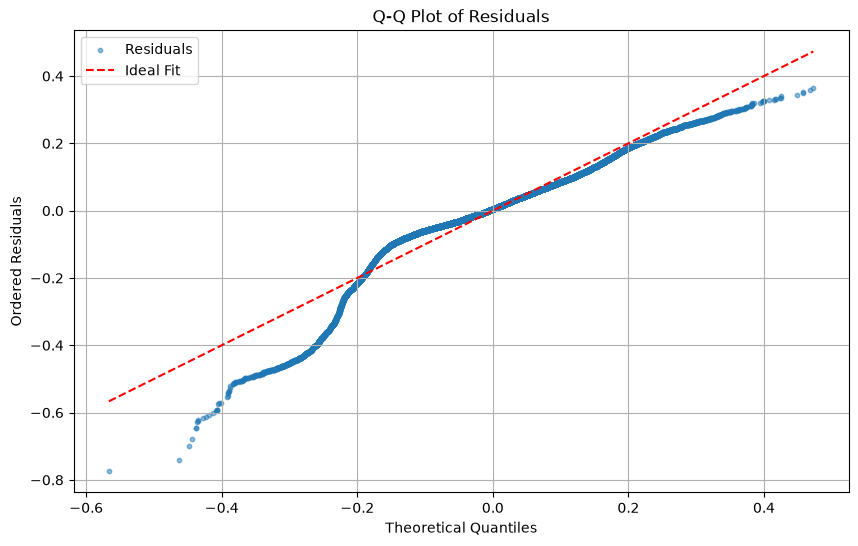

In [28]:
q_q_plot(y, y_pred)

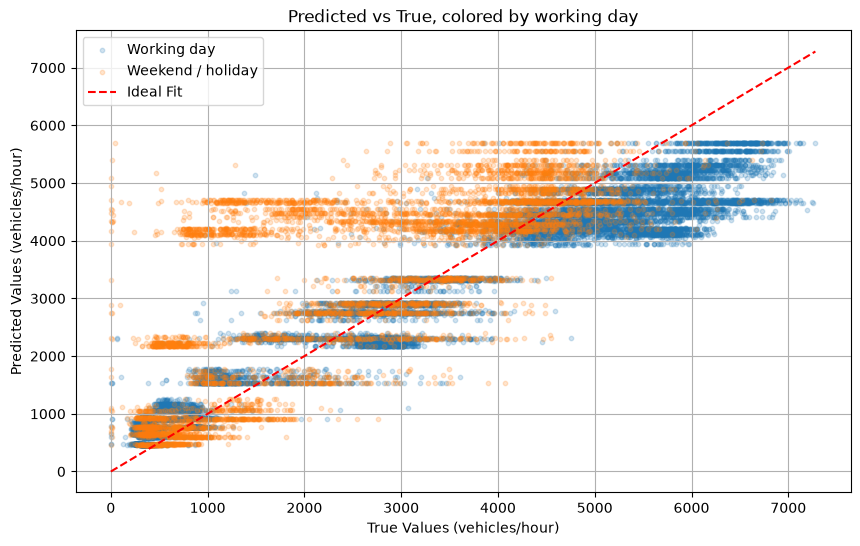

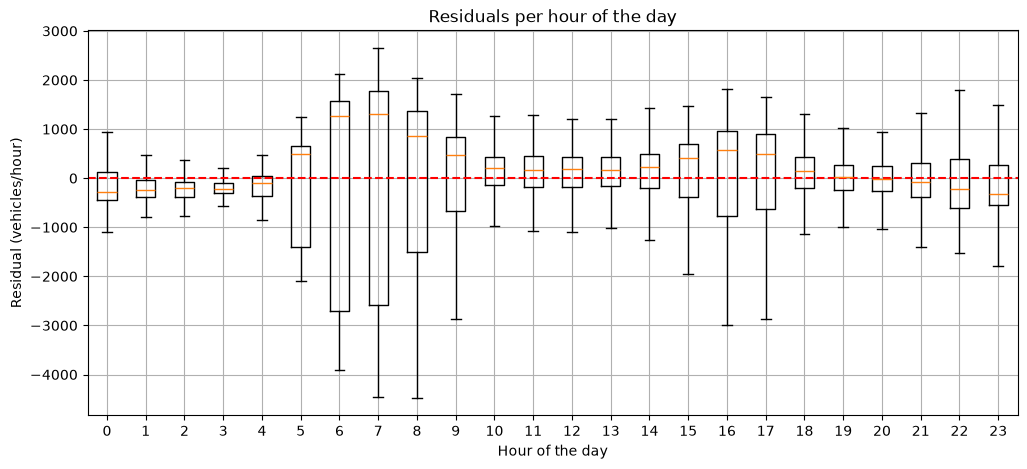

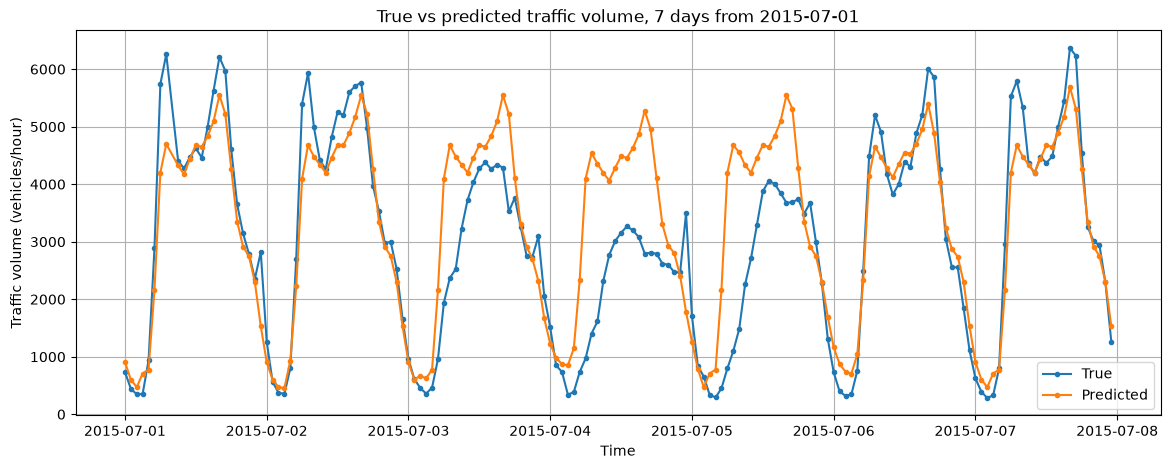

Number of training samples: 21341
Number of distinct predicted values: 221


In [29]:
# Plot other visualizations too to better analyze the predictions.

y_true_veh = to_vehicles(y)
y_pred_veh = to_vehicles(y_pred)
residuals_veh = y_true_veh - y_pred_veh

pred_vs_true_by_group(y_true_veh, y_pred_veh, is_workingday)
residuals_by_hour(residuals_veh, hours)
predictions_vs_time(y_true_veh, y_pred_veh)

# How many different values can this model actually output? Every
# prediction is bias + (one hour weight) + (one weather weight), so the
# model is restricted to a small, finite set of answers.
print("Number of training samples:", len(y_pred))
print("Number of distinct predicted values:",
      len(np.unique(np.round(y_pred, 6))))


> **Question:**
> 
> Does the polynomial model appear to capture relationships that the linear model
could not?
>
> Did this choice fix the systematic deviations previously observed?


**Answers**:
The polynomial model doesn't appear to capture relationships that the linear model could not. In fact, the visualizations generated are pretty much identical to the ones generated using the linear model. The same patterns observed in the linear model are still present in the polynomial model, so this choice doesn't fix the systematic deviations.</br>
The relative difference observed in these models are small (<3% in error, ~0.5% in score), which explains why the visualizations being so similar to each other.</br>
Therefore, the polynomial model adds some flexibility but doesn't change the relationship learned from the data significantly.

---
## **Count Data and Model Assumptions**

> **IMPORTANT:** This section is optional and will yield **additional 1.0 points**
> to your assignment.
> We recommend you finish the mandatory sections above before attempting to
> switch to additional assumptions and model decisions this section introduces.
>
> Despite this section being optional, we strongly advise you on exploring
> the following models, not only as an additional model to your toolbox, but
> from the modeling perspective of statistical learning.

\
In the previous sections we used linear regression and polynomial models
to predict the hourly traffic volume.
However, the target variable in this dataset has a particular characteristic,
it represents a **count**.

This is important because, when we were stating the assumptions in the linear model,
we had no hard assumption on the target nature, it was a real number.
In counting problems, the target is a positive integer number with specific
characteristics that are ignored.

Therefore, a possible direction of improvement is choosing the model that best
aligns with our problem, exploiting the domain knowledge we have to produce better
estimators.

In this section, we are going to use a new linear model with a different
probabilistic assumption for the target variable.

### **Poisson distribution**

A common model for count data is the **Poisson distribution**.
This distribution describes the probability of observing a number of events
during a fixed interval.

For example, the number of students achieving a low and high mark in an exam,
the number of meteorites that strike Earth in a year, or the number of vehicles
crossing a sensor in one hour.

The Poisson distribution is parameterized by a rate parameter $\lambda > 0$,
which represents the expected number of events in a time unit.

The probability of observing a value $y$ is

$$p(y \mid \lambda) = \frac{\lambda^y e^{-\lambda}}{y!}.$$

In this model, both the mean and the variance are equal to $\lambda$.
Therefore, when predicting, returning the expected count value $\hat{y}$ is
equivalent to returning $\lambda$ itself.

### **Poisson Regression**
Poisson regression is a special case of the Generalized Linear Models along with
Linear and Logistic regression.
The idea here is to model $\lambda$ as a function of the input $x$ and parameters
$\beta$ and describe $p(y \mid x, \beta) = p(y \mid \lambda)$.

Again, as a linear model, we want to relate the linear combination
$\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$ to this new parameter $\lambda$,
that is strictly positive.

To make this to happen, we define a **link function** $g$ such that $g(\lambda)$
can vary from -$\infty$ to $\infty$, thus allowing that

$$g(\lambda) = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n,$$
as $\beta$ and $x$ are unconstrained.

A common link function used in Poisson regression is the $\log$, making

$$\hat{y} = \lambda = \exp(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n),$$
turning the previously unconstrained prediction in a strictly positive count
parameter, and then addressing a probability using the Poisson distribution.

#### **Implementation**

(1.0 points) Derive the loss function of the Poisson Regression,

$$-\log \mathcal{L}(\beta) = -\sum_{i=1}^n \log p(y^i \mid x^i, \beta),$$
using the Poisson distribution instead of the Gaussian distribution for $p(y^i \mid x^i, \beta)$.

**Hint:** You can ignore constant terms and scales in the objective function to
obtain a MSE-like gradient.

> **Question:**
>
> Is the negative log-likelihood the same?
>
> Is it equivalent to a Linear regressor predicting $\log y$ instead of $y$?

**Answers**:

Derivation:

$$p(y \mid \lambda) = \frac{\lambda^y e^{-\lambda}}{y!},$$

$$\log p(y \mid \lambda) = y\log \lambda - \lambda - \log y!,$$

But $\lambda$ is defined such as

$$\lambda = \exp(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n) = \exp(x^T \beta) = \hat{y},$$

And then

$$\log p(y \mid x, \beta) = y(x^T \beta) - \exp(x^T \beta) - \log y!,$$

$$\log p(y \mid x, \beta) = y \log \hat{y} - \hat{y} - \log y!.$$

Thus, minimizing $-\log \mathcal{L}(\beta)$, yield to

$$-\log \mathcal{L}(\beta) \propto \sum_{i=1}^n \hat{y_i} - y_i \log \hat{y_i}.$$

Since the factorial term involves just $y$.

Answering questions:

1. No, the negative log-likelihood is not the same as in linear regression. For Poisson assumption the negative log-likelihood is the one derivated above.

2. No, using a log link function in Poisson regression does not mean that it is equivalent to performing linear regression on $\log y$. If we were predicting $\log y$ with a linear regressor, it would be something like $\sum_{i=1}^n (\log y_i - \log \hat{y_i})^2.$

---
Implement this regression using the same pattern as the `LinearRegression` and
train a Poisson regression model using the same training dataset used
previously, selecting appropriate learning rates.

> **Hint:** the counts in this dataset are large, so $\exp(x^T\beta)$ can easily
> overflow during the first iterations. If you run into `inf`/`nan`, think about
> the scale of your features and of the initial prediction before blaming the
> learning rate alone.

In [30]:
class PoissonRegression:
    def __init__(
        self,
        learning_rate: float = 0.01,
        n_iterations: int = 1000,
        err_tolerance: float = 1e-5,
    ) -> None:
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.err_tolerance = err_tolerance
        self.weights: NDArray[np.float64] | None = None
        self.bias: float | None = None

    def fit(self, X: NDArray[np.float64], y: NDArray[np.float64]) -> None:
        n_samples, n_features = X.shape
        weights = np.zeros(n_features)
        bias = np.log(np.mean(y))
        prev_cost = np.inf

        print("----------------------------------------")
        print("   Training poisson regression model    ")
        print(f"  Learning rate = {self.learning_rate} ")
        print("----------------------------------------")

        # Gradient Descent loop, with a limit of n_iterations. 
        for i in range(self.n_iterations):
            # Current prediction and cost. Cost is based on MSE function.
            log_y_pred = np.dot(X, weights) + bias
            y_pred = np.exp(log_y_pred)
            curr_cost = np.mean(y_pred - y*log_y_pred)

            # Print epoch and cost every 100 epochs to prevent output
            # flooding.
            if (i % 100 == 0):
                print(f"----- Current epoch: {i}... -----")
                print(f"Cost: {curr_cost}")

            # Stop criteria: when cost is smaller than tolerance (in this
            # case, set to 1e-5).
            if np.abs(prev_cost - curr_cost) < self.err_tolerance:
                print(f"Best weights found at epoch {i-1}")
                break

            prev_cost = curr_cost

            # Difference, needed to calculate the partial derivatives
            # to get the gradient
            diff = y_pred - y

            # Partial derivative of the MSE function for a weight 
            dw = np.dot(X.T, diff) / n_samples

            # And for the bias
            db = np.mean(diff)

            # Updating the weights and the bias value to the next iteration.
            weights = weights - self.learning_rate * dw
            bias = bias - self.learning_rate * db

        self.weights = weights
        self.bias = bias

        print("----------------------------------------")
        print(f"      Done training on epoch {i}       ")
        print("----------------------------------------")
        print("----- Best weights found: -----")
        print(f"Bias (w0) = {bias}")
        for i in range(n_features):
            print(f"w{i+1} = {weights[i]}")
        print("\n")
    
    def predict(self, X: NDArray[np.float64]) -> NDArray[np.float64]:
        assert self.weights is not None and self.bias is not None, "Model is not trained yet"
        
        y_pred = np.exp(np.dot(X, self.weights) + self.bias)
        return y_pred

In [31]:
def preprocess_data_poisson(df: pd.DataFrame) -> tuple[NDArray[np.float64], NDArray[np.float64]]:

    expected_hours = list(range(24))
    expected_weather = [
    'Rain', 'Clear', 'Clouds', 'Haze', 'Thunderstorm', 
    'Mist', 'Drizzle', 'Fog', 'Smoke', 'Snow'
    ]

    df['hr'] = pd.Categorical(df['hr'], categories=expected_hours)
    df['weather'] = pd.Categorical(df['weather'], categories=expected_weather)

    one_hot_df = pd.get_dummies(df[['hr', 'weather']], dtype=int)

    X = one_hot_df.to_numpy()

    row_y = df['traffic_volume'].to_numpy()
    y = row_y[:, np.newaxis]
    y = y.ravel()

    print("Shape of X (should be n_samples, 34):",
          np.shape(X))
    print("Shape of y (should be n_samples,):",
          np.shape(y))

    return (X, y)

Shape of X (should be n_samples, 34): (21341, 34)
Shape of y (should be n_samples,): (21341,)
----------------------------------------
   Training poisson regression model    
  Learning rate = 0.0001 
----------------------------------------
----- Current epoch: 0... -----
Cost: -23255.341165290214
----- Current epoch: 100... -----
Cost: -23720.9661720016
----- Current epoch: 200... -----
Cost: -23789.071006922542
----- Current epoch: 300... -----
Cost: -23808.96372733518
----- Current epoch: 400... -----
Cost: -23816.912045008397
----- Current epoch: 500... -----
Cost: -23820.644434433176
----- Current epoch: 600... -----
Cost: -23822.57563529908
----- Current epoch: 700... -----
Cost: -23823.642922445262
----- Current epoch: 800... -----
Cost: -23824.26200357228
----- Current epoch: 900... -----
Cost: -23824.634739911646
----- Current epoch: 1000... -----
Cost: -23824.86590202325
----- Current epoch: 1100... -----
Cost: -23825.01275512694
----- Current epoch: 1200... -----
Cost: -23

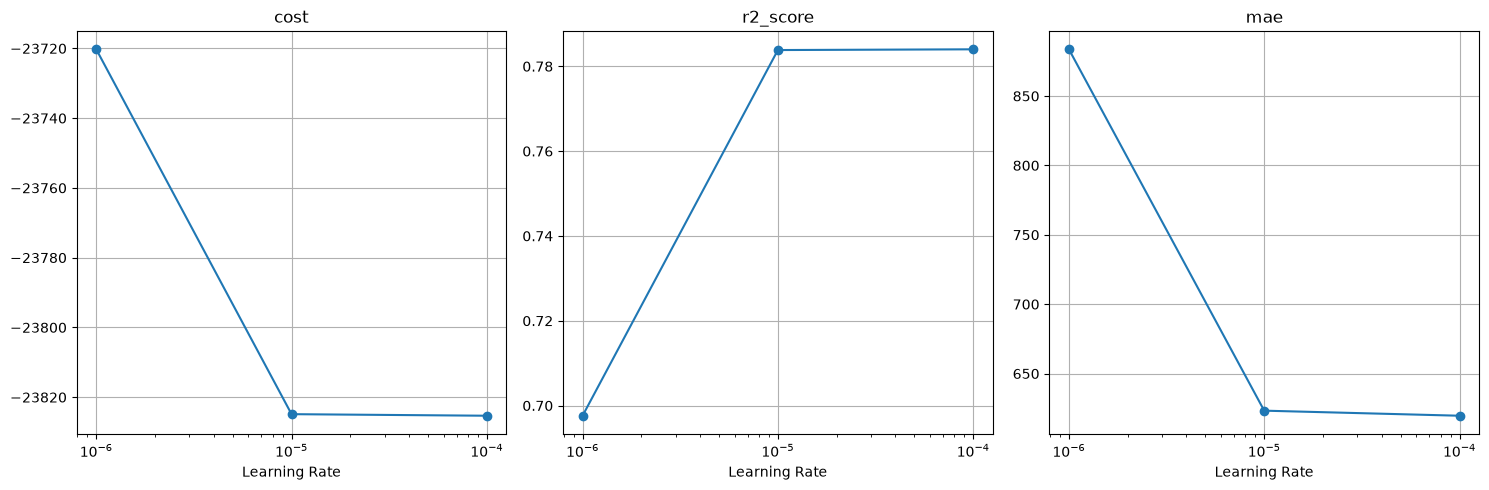

In [32]:
# Implement and train the poisson regression models here.

X, y = preprocess_data_poisson(train_df)

# You can experiment with a pre-defined set of learning rates or
# with a range of learning rates (e.g. logarithmically spaced)
lrs = [1e-4, 1e-5, 1e-6]

performances = {
    "cost": [],
    "r2_score": [],
    "mae": [],
    # Add other metrics here if you implemented them
}

for lr in lrs:
    model = PoissonRegression(learning_rate=lr, n_iterations=10000)
    model.fit(X, y)
    y_pred = model.predict(X)

    cost_score = np.mean(y_pred - y*np.log(y_pred))
    r2 = r2_score(y, y_pred)
    mae_score = mae(y, y_pred)

    performances["cost"].append(cost_score)
    performances["r2_score"].append(r2)
    performances["mae"].append(mae_score)

plot_results(lrs, performances, "Learning Rate", "log")

> **Question:**
>
> Compare the performance of the Poisson models with the Linear Regression model.
> Even though both models rely on a linear combination of the features,
> their predictions are not computed in the same way.
>
> $\hat{y}=x^T\beta$
>
> $\lambda=\exp(x^T\beta)$
>
> Are the predictive performances equivalent?
> Which model appears to produce predictions that better match the data?
>
> Explain why two models that both use a linear predictor can still behave
> very differently. Consider the distributional assumptions and the
> transformation applied to the output.

**Answers**:
The predictive performances of the Poisson and Linear Regression models are similar, but not equivalent. In our experiments, the Poisson Regression model achieved a better R² score than the Linear Regression and Polynomial Regression models when using the same fixed set of features. Therefore, the Poisson model appears to produce predictions that better match the observed data.</br>
Although both models use a linear predictor, they compute their predictions differently. Linear Regression directly uses the linear predictor as the predicted value, $\hat{y}=x^T\beta$. In Poisson Regression, the linear predictor is transformed using the exponential function, $\lambda=\exp(x^T\beta)$, before producing the prediction. The error assumptions in the two models are different, while Linear Regression assumes normally distributed errors, Poisson Regression models the target as a Poisson-distributed count. These differences in the distributional assumptions and in the output transformation can make the two models behave very differently, even though both rely on a linear combination of the same features.

---
### **Visualizing Predictions**

Check how the predictions change when moving from the **Gaussian assumption**
used in linear regression to the **Poisson assumption** used in Poisson regression.

Plot the predicted values against the observed values and compare the
distribution of points with the plots obtained previously.

Pay attention to how the **shape of the point cloud** changes under the
different modeling assumptions.


----------------------------------------
   Training poisson regression model    
  Learning rate = 0.0001 
----------------------------------------
----- Current epoch: 0... -----
Cost: -23255.341165290214
----- Current epoch: 100... -----
Cost: -23720.9661720016
----- Current epoch: 200... -----
Cost: -23789.071006922542
----- Current epoch: 300... -----
Cost: -23808.96372733518
----- Current epoch: 400... -----
Cost: -23816.912045008397
----- Current epoch: 500... -----
Cost: -23820.644434433176
----- Current epoch: 600... -----
Cost: -23822.57563529908
----- Current epoch: 700... -----
Cost: -23823.642922445262
----- Current epoch: 800... -----
Cost: -23824.26200357228
----- Current epoch: 900... -----
Cost: -23824.634739911646
----- Current epoch: 1000... -----
Cost: -23824.86590202325
----- Current epoch: 1100... -----
Cost: -23825.01275512694
----- Current epoch: 1200... -----
Cost: -23825.1079307366
----- Current epoch: 1300... -----
Cost: -23825.17067194152
----- Current epoch

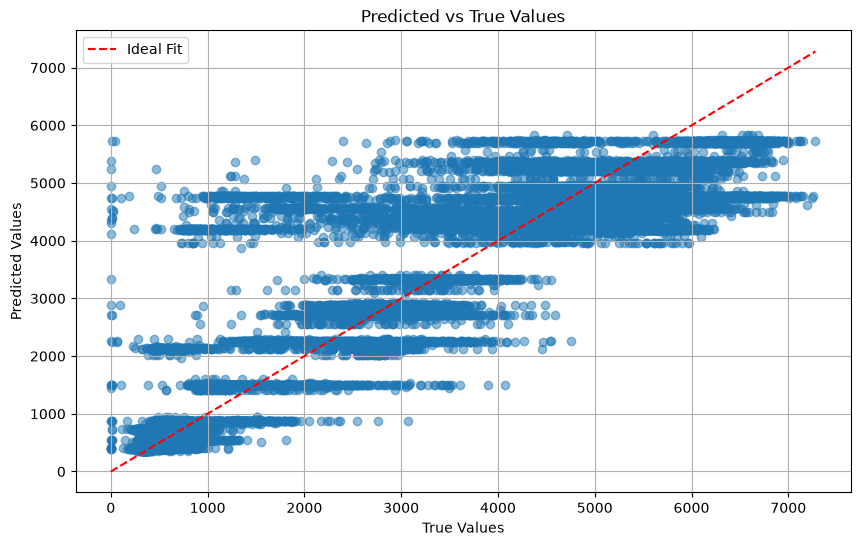

In [33]:
best_lr = 1e-4 # Choose the best learning rate based on the previous graphs

best_poisson_model = PoissonRegression(learning_rate=best_lr, n_iterations=10000)
best_poisson_model.fit(X, y)
y_pred = best_poisson_model.predict(X)

pred_vs_true_plot(y, y_pred)

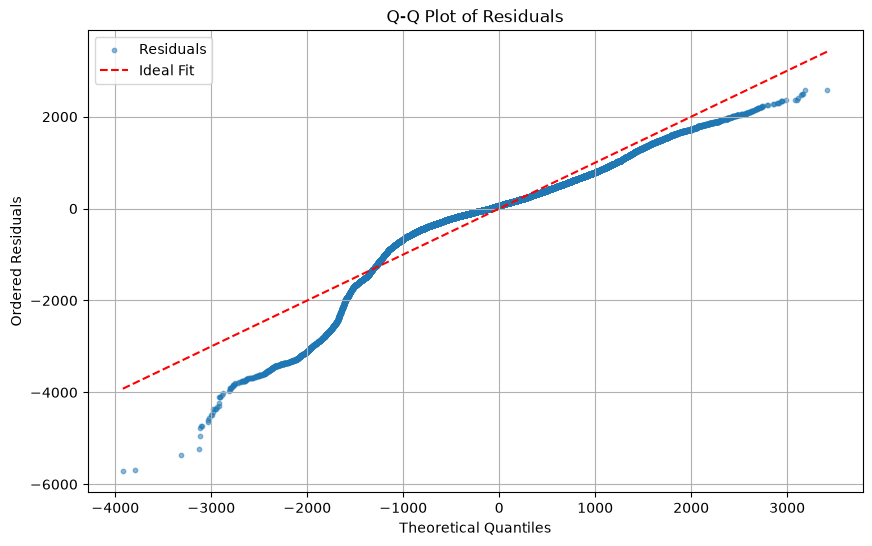

In [34]:
q_q_plot(y, y_pred)

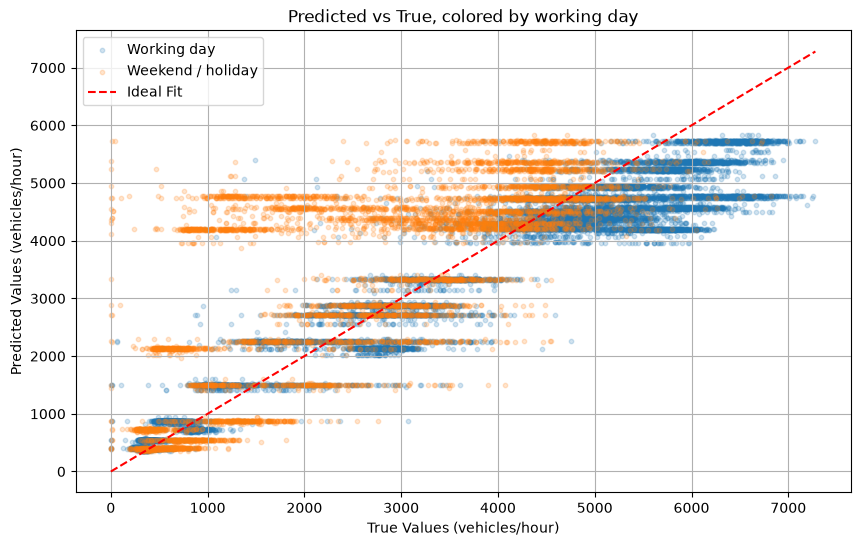

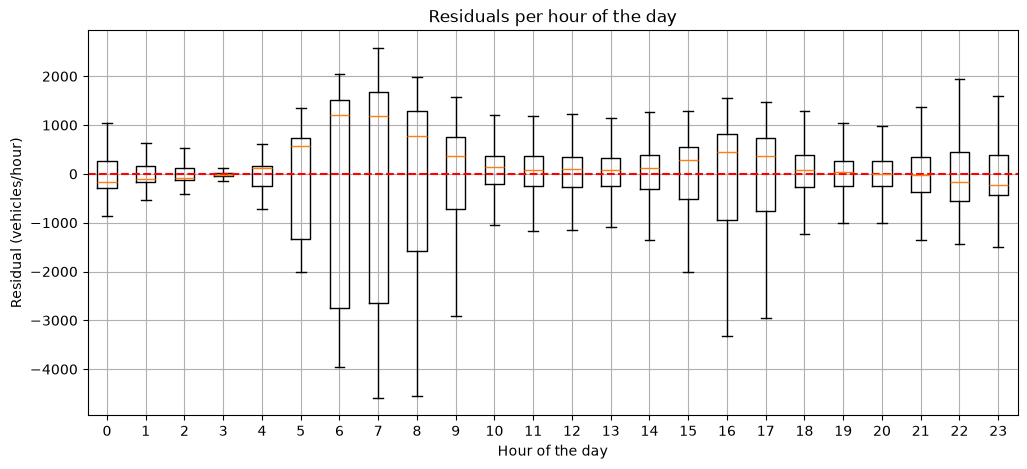

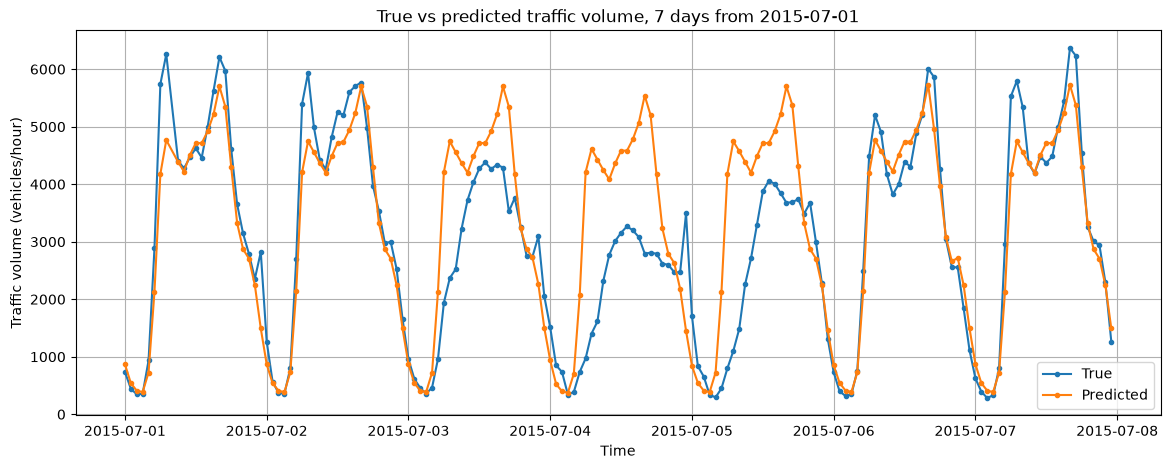

Number of training samples: 21341
Number of distinct predicted values: 221


In [35]:
# Plot other visualizations too to better analyze the predictions.
residuals = y - y_pred

pred_vs_true_by_group(y, y_pred, is_workingday)
residuals_by_hour(residuals, hours)
predictions_vs_time(y, y_pred)

# How many different values can this model actually output? Every
# prediction is bias + (one hour weight) + (one weather weight), so the
# model is restricted to a small, finite set of answers.
print("Number of training samples:", len(y_pred))
print("Number of distinct predicted values:",
      len(np.unique(np.round(y_pred, 6))))


> **Question:**
>
> Compare the prediction plots obtained with the **Linear**, **Polynomial**, and
> **Poisson** models.
>
> - Does the Poisson model change the overall shape of the prediction cloud?
> - Do the predictions appear more consistent with the count nature of the data?
> - Are extreme values predicted differently?
>
> Based on the visualization, what differences arise from changing the
> probabilistic assumption of the model?

**Answers**:
The prediction plots for the Linear, Polynomial, and Poisson models show very similar overall patterns. The Poisson model does not significantly change the shape of the prediction cloud, and it still presents the same systematic deviations observed in the other models.</br>
The Poisson model is more consistent with the count nature of the target because it models the response as a Poisson-distributed count and uses an exponential transformation to ensure non-negative predictions. This could explain the better R² score. However, this does not completely solve the prediction errors. The model still has difficulty capturing some extreme values, just like the previous ones.</br>
Changing the probabilistic assumption from a Gaussian-based Linear Regression model to a Poisson model changes the way the target is modeled and how the predictions are transformed, but it does not provide the model with additional information about the traffic volume. As a result, the Poisson model behaves somewhat differently, but many of the same limitations remain.

---
### **Residual Diagnostics for Poisson Regression**

In the previous sections we used a **Q–Q plot** to evaluate whether the
residuals followed a **Normal distribution**. This diagnostic was meaningful
because linear regression was derived under the assumption that the error term
follows a Gaussian distribution,

$$\epsilon \sim \mathcal{N}(0,\sigma^2).$$

Under this assumption, if the model is well specified, the residual

$$r_i = y_i - \hat{y}_i,$$
should also resemble a Normal distribution.

The Q–Q plot therefore allowed us to visually verify whether this assumption was
reasonable.
However, this reasoning no longer applies to **Poisson regression**, as the
target $y$ now is assumed to be drawn from a Poisson distribution with

$$y \sim \text{Poisson}(\lambda), \qquad \lambda = \exp(x^T\beta).$$

Because of this, the residuals are **not expected to follow a Normal
distribution**, even if the model is correct.
A Q–Q plot comparing them to a Normal distribution therefore does not test a
relevant assumption.


---
### **Polynomial Poisson Regression**

As we observed an increased performance by introducing polynomial
features, allowing the model to capture nonlinear relationships between the
predictors and the target.
The same idea can be applied to **Poisson regression**.

Instead of changing the probabilistic model, we only change the
**feature representation**. The Poisson model still assumes that the
expected count follows an exponential transformation of a linear
predictor,

$$\lambda = \exp(x^T\beta).$$
with $x$ now containing polynomial terms.

Continue exploring Poisson models with more complex relationships, find the best
degrees and learning rates.


0 new features has been generated
----------------------------------------
   Training poisson regression model    
  Learning rate = 0.0001 
----------------------------------------
----- Current epoch: 0... -----
Cost: -23255.341165290214
----- Current epoch: 100... -----
Cost: -23720.9661720016
----- Current epoch: 200... -----
Cost: -23789.071006922542
----- Current epoch: 300... -----
Cost: -23808.96372733518
----- Current epoch: 400... -----
Cost: -23816.912045008397
----- Current epoch: 500... -----
Cost: -23820.644434433176
----- Current epoch: 600... -----
Cost: -23822.57563529908
----- Current epoch: 700... -----
Cost: -23823.642922445262
----- Current epoch: 800... -----
Cost: -23824.26200357228
----- Current epoch: 900... -----
Cost: -23824.634739911646
----- Current epoch: 1000... -----
Cost: -23824.86590202325
----- Current epoch: 1100... -----
Cost: -23825.01275512694
----- Current epoch: 1200... -----
Cost: -23825.1079307366
----- Current epoch: 1300... -----
Cost: -238

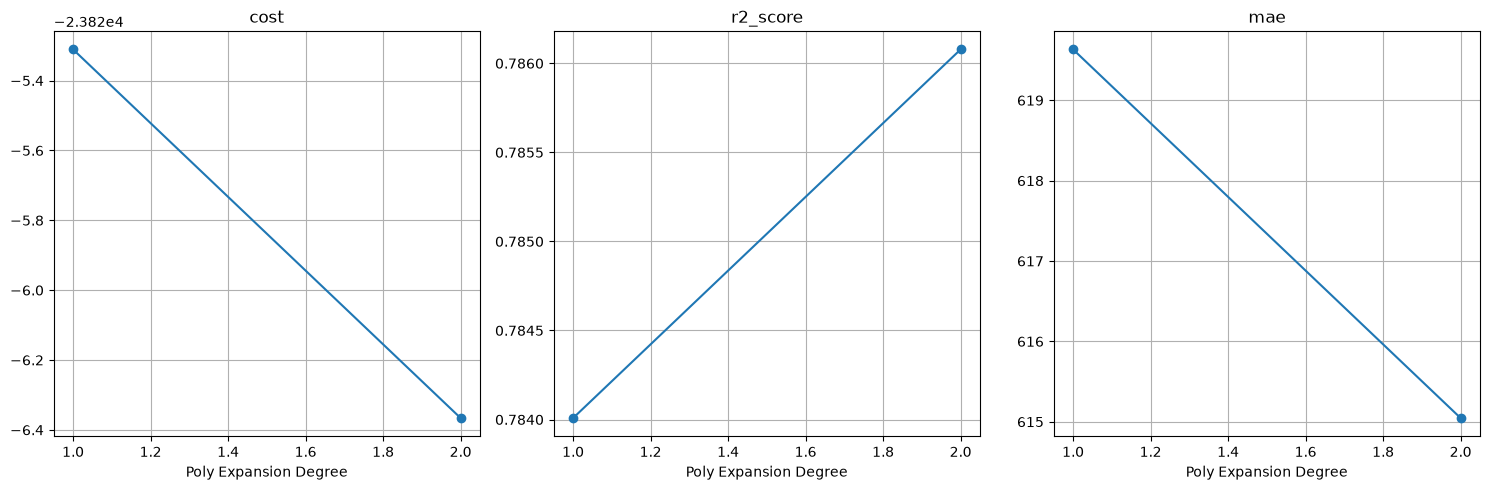

In [36]:
# Implement and train the polynomial poisson regression models here using the 
# polynomial_expansion function to transform the features before training the linear regression model.

# Experiment with different degrees and analyze the results to choose the best combination
# of learning rate and degree for the polynomial regression model.

performances = {
    "cost": [],
    "r2_score": [],
    "mae": [],
    # Add other metrics here if you implemented them
}

degrees = [1, 2] # 3 or more is unviable
for d in degrees:
    model = PoissonRegression(learning_rate=1e-4, n_iterations=3000)
    X_poly = polynomial_expansion(X, d)
    model.fit(X_poly, y)
    y_pred = model.predict(X_poly)

    cost_score = np.mean(y_pred - y*np.log(y_pred))
    r2 = r2_score(y, y_pred)
    mae_score = mae(y, y_pred)

    performances["cost"].append(cost_score)
    performances["r2_score"].append(r2)
    performances["mae"].append(mae_score)


plot_results(degrees, performances, "Poly Expansion Degree", "linear")

595 new features has been generated
----------------------------------------
   Training poisson regression model    
  Learning rate = 0.0001 
----------------------------------------
----- Current epoch: 0... -----
Cost: -23255.341165290214
----- Current epoch: 100... -----
Cost: -23795.53933822236
----- Current epoch: 200... -----
Cost: -23818.54737554026
----- Current epoch: 300... -----
Cost: -23823.122787538534
----- Current epoch: 400... -----
Cost: -23824.53855925735
----- Current epoch: 500... -----
Cost: -23825.112208214756
----- Current epoch: 600... -----
Cost: -23825.40043657452
----- Current epoch: 700... -----
Cost: -23825.57348631054
----- Current epoch: 800... -----
Cost: -23825.692632725066
----- Current epoch: 900... -----
Cost: -23825.782865223773
----- Current epoch: 1000... -----
Cost: -23825.855537129115
----- Current epoch: 1100... -----
Cost: -23825.91636817288
----- Current epoch: 1200... -----
Cost: -23825.96855034633
----- Current epoch: 1300... -----
Cost: 

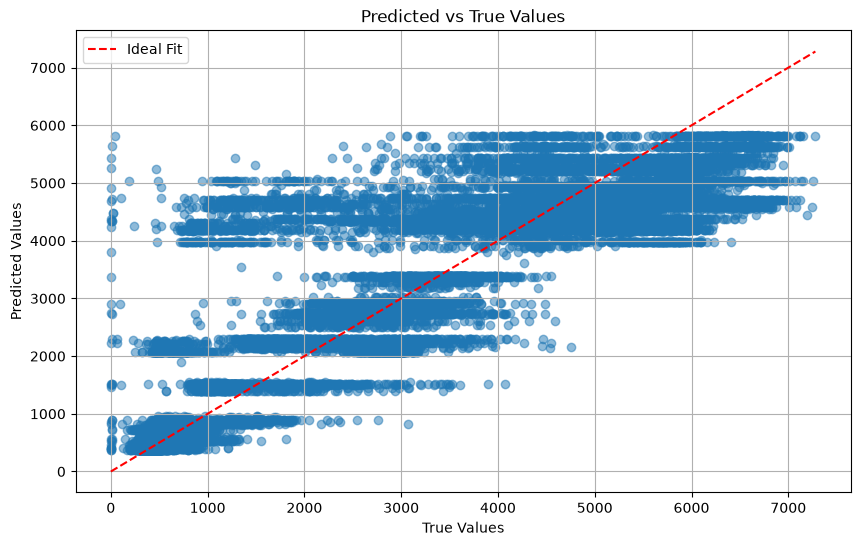

In [37]:
best_lr = 1e-4 # Choose the best learning rate based on the previous graphs

best_degree = 2 # Choose the best degree based on experimentation with different degrees and analyzing the results

X_poly = polynomial_expansion(X, best_degree)

best_poisson_poly_model = PoissonRegression(learning_rate=best_lr, n_iterations=3000)
best_poisson_poly_model.fit(X_poly, y)
y_pred = best_poisson_poly_model.predict(X_poly)

pred_vs_true_plot(y, y_pred)

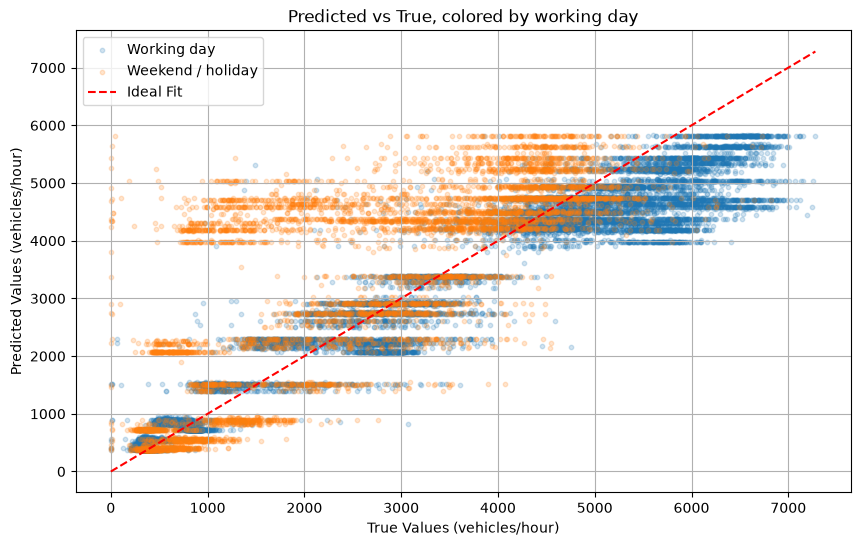

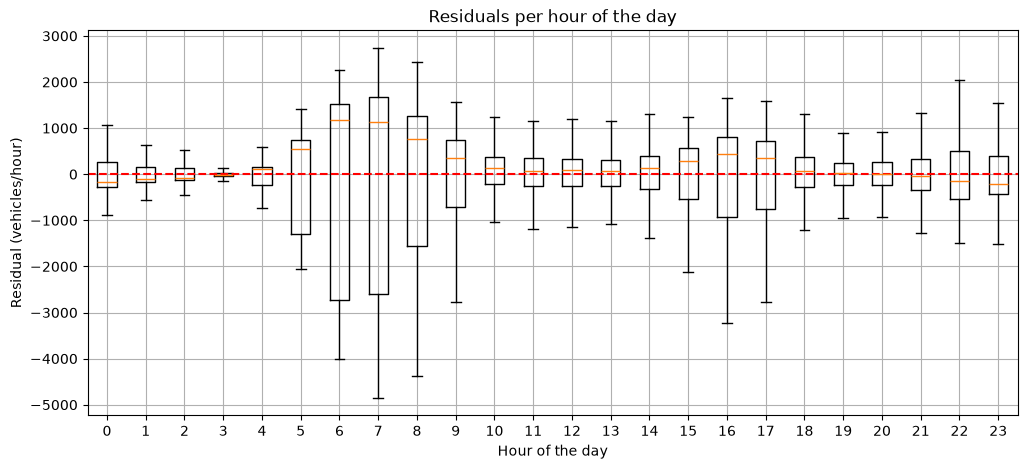

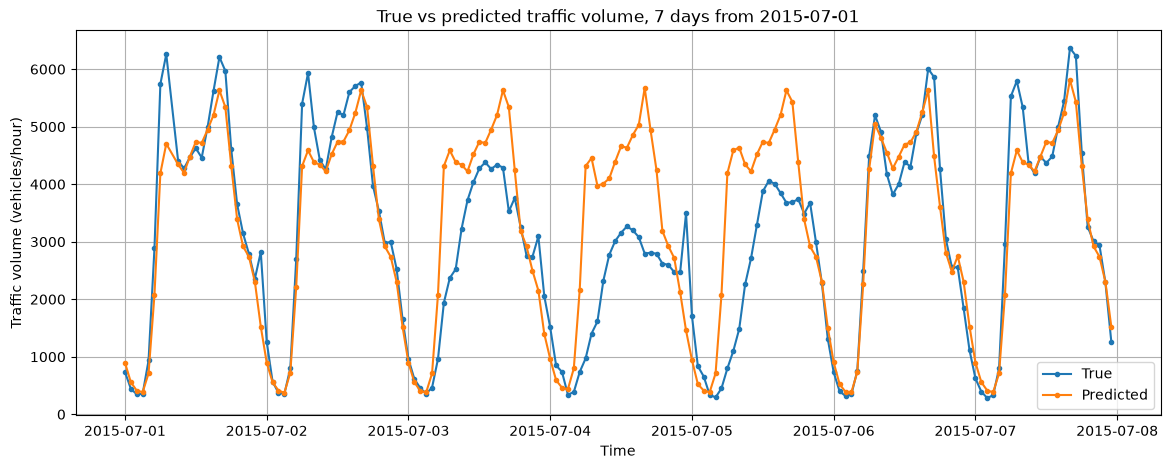

Number of training samples: 21341
Number of distinct predicted values: 221


In [38]:
# Plot other visualizations too to better analyze the predictions.
residuals = y - y_pred

pred_vs_true_by_group(y, y_pred, is_workingday)
residuals_by_hour(residuals, hours)
predictions_vs_time(y, y_pred)

# How many different values can this model actually output? Every
# prediction is bias + (one hour weight) + (one weather weight), so the
# model is restricted to a small, finite set of answers.
print("Number of training samples:", len(y_pred))
print("Number of distinct predicted values:",
      len(np.unique(np.round(y_pred, 6))))

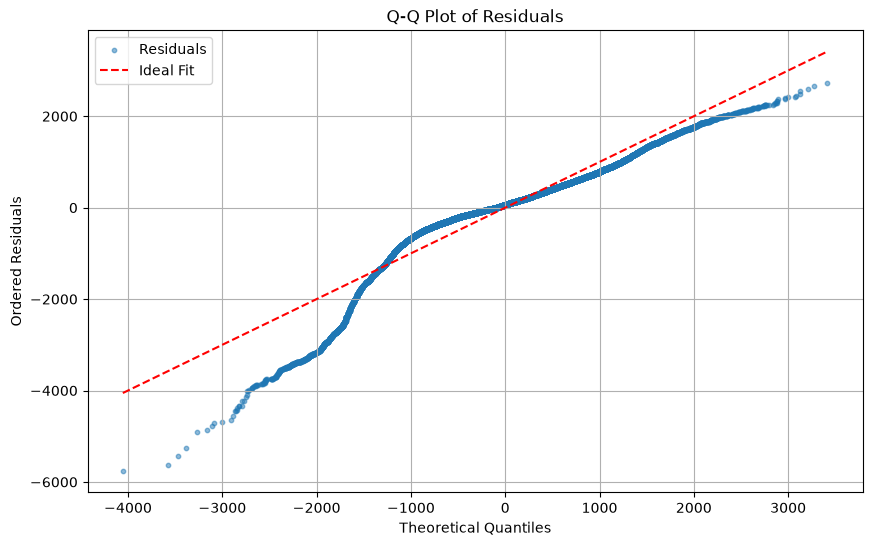

In [39]:
q_q_plot(y, y_pred)

> **Question:**
>
> Compare the residual structure of the **Poisson** and
> **Polynomial Poisson** models.
>
> Was the improvement similar to the Linear Regression counterparts?
> How are they different?

**Answers**:
Both the Poisson and Polynomial Poisson models show basically the same systematic deviations in their residuals, similar to those observed in the Gaussian models.</br>
The improvement is similar to what we observed with the Linear Regression counterparts. The Polynomial Poisson model achieved a slightly higher R² score (0.786) compared to the Linear Poisson model (0.784), but the difference is very small.</br>
This suggests that adding polynomial features does not substantially improve the model's ability to capture the underlying patterns with this features setup. The main systematic deviations remain in both models, indicating that the additional polynomial complexity does not address the main limitations of the model, which are likely related to the limited set of predictors.

---
## **Final Model Comparison**


Until this point, all analysis and decisions were made using only the **training data**.  
The **test dataset** has remained untouched so that it can provide an unbiased
evaluation of the final models.

This is important in machine learning, as our job is not to train a model that can
copy the behavior in data, but to generalize to unseen observations.
The decisions made to improve the performance based only on training data may or
may not reflect in the test data, indicating an under- or overfitting.

(1.0 points) Before using the test dataset, look at all your decisions and assumptions done
on each model and discuss them.
In real life, this would be the last step before the deployment of our models.

> **Question:**
>
> Revisiting all the models you have trained, what are the main differences between them in performance and assumptions?
> 
> If you could select only one, based on your analysis, which one would you choose and why?
> Also discuss about its possible limitations, what it doesn't solve?
>
> How do you think it will perform on unseen data?

**Answers**:
The main differences between the four models are the type of predictor (linear or polynomial) and the error distribution assumption (Gaussian or Poisson). The simplest model, Linear-Gaussian Regression, had the fastest training time, followed by Linear-Poisson Regression. The polynomial models were the least efficient, since they required considerably more time to train but did not show significant improvements compared to their corresponding linear versions.</br>
Based on our analysis, we would choose the Linear-Poisson model. All models presented basically the same systematic deviations, but the Linear-Poisson model achieved the second best R² score among them while still having a fast training time. Additionally, its Poisson assumption is more appropriate for the count nature of the target.</br>
The main limitation of all these models is the limited set of features used to represent the data. Because the models rely mainly on hour and weather conditions, they cannot capture particularities of individual observations or other factors that may affect traffic volume. The polynomial expansion can model more complex relationships between the features, but it does not add new information to the model.</br>
We expect the Linear-Poisson model to perform reasonably well on unseen data, with performance relatively close to what was observed during training. Since the prediction plots did not show clear signs of overfitting, we expect the model to generalize reasonably well, although the same systematic deviations and difficulty in predicting extreme values may remain.

---

(0.5 points) Now evaluate all trained models on the **test dataset** using the same metrics
used previously.
Compute the predictions and compare their performance.

In [40]:
# Comparison code here, make sure you have the final models

# Since there was no changes after best_XXX_model, we will use this variables to compare models

X_test, y_test = preprocess_data(test_df)
y_test = y_test.ravel()
X_test_poly = polynomial_expansion(X_test, 2)

X_test_poisson, y_test_poisson = preprocess_data_poisson(test_df)
X_test_poisson_poly = polynomial_expansion(X_test_poisson, 2)

linear_gaussian = best_linear_model.predict(X_test)
poly_gaussian = best_poly_model.predict(X_test_poly)
linear_poisson = best_poisson_model.predict(X_test_poisson)
poly_poisson = best_poisson_poly_model.predict(X_test_poisson_poly)

# You can create plots comparing the predictions of the different models, e.g., predicted vs true values for each model, residual plots, etc.
# Measure the performance of each model using the implemented metrics and compare them in a table or bar plot.
# Feel free to explore other ways to compare the models and analyze their predictions.

Shape of X (should be n_samples, 34): (5336, 34)
Shape of y (should be n_samples,): (5336, 1)
595 new features has been generated
Shape of X (should be n_samples, 34): (5336, 34)
Shape of y (should be n_samples,): (5336,)
595 new features has been generated


In [41]:
results = {
    "Linear-Gaussian": {
        "R²": r2_score(y_test, linear_gaussian),
        "MAE": mae(y_test, linear_gaussian),
    },
    "Polynomial-Gaussian": {
        "R²": r2_score(y_test, poly_gaussian),
        "MAE": mae(y_test, poly_gaussian),
    },
    "Linear-Poisson": {
        "R²": r2_score(y_test_poisson, linear_poisson),
        "MAE": mae(y_test_poisson, linear_poisson),
    },
    "Polynomial-Poisson": {
        "R²": r2_score(y_test_poisson, poly_poisson),
        "MAE": mae(y_test_poisson, poly_poisson),
    },
}

for model, metrics in results.items():
    print(f"{model}: R² = {metrics['R²']:.4f}, MAE = {metrics['MAE']:.2f}")

Linear-Gaussian: R² = 0.7831, MAE = 0.09
Polynomial-Gaussian: R² = 0.7887, MAE = 0.09
Linear-Poisson: R² = 0.7960, MAE = 611.92
Polynomial-Poisson: R² = 0.7965, MAE = 606.64





> **Question:**
>
> Compare the performance of all models on the **test dataset**.
>
> Are the differences between the models large or small?
> 
> Does the test behave the same as the training results?
> Did you make the right choices when you selected the "best" model based on the training data?
>
> Finally, make hypothesis on the whole result, why the test behaves differently
from the train? What different decisions would you have made if you had access to the
test data?


**Answers**:
All of the models had similar perfomances and the same systematic deviations, leading to a very small difference between each other.</br>
The Poisson models achieved a good performance on the test dataset, with a R² of 0.7960 for Linear and R² of 0.7965 for Polynomial. While Gaussian models were slightly worse, but similar to training score. These data shows that adding polynomial features provided only a very small improvement.</br>
Overall, the test results were consistents with training results. The Linear-Poisson remained as the second better, behind only Polynomial-Poisson, but by a tiny difference and much less complexity.</br>
The results suggest that the Poisson formulation is more suitable for this target variable, since it maintained a strong performance on unseen data. The fact that the test performance was close to the training performance also suggests that the models did not suffer from severe overfitting.</br>
If we had access to the test data when making our decisions, we would still choose the Linear-Poisson model. Given its strong test performance, significantly simpler structure, and appropriate assumption for count data, there would be little reason to prefer the more complex polynomial models unless they showed a substantial improvement.

---
## **Assignment submission**


This notebook must be filled with your solution and submitted on the Assignment's entry at our Google Classroom page.
Before submitting, make sure that
- Your notebook runs end-to-end without errors.
- All the plots are included in the notebook.
- The notebook must be self-contained and there is no external dependency.

**Important: Only one member of the group should submit the solution.**

### **Policy for late submissions**

You are NOT encouraged to submit the solution after the deadline; however, in this case, the following penalties hold:

* 25% of the grade for 1-day late submission;
* 50% of the grade for 2-day late submission;
* 75% of the grade for 3-day late submission.